# 02 – Nested CV: Dört Üye, Dört Yöntem
Bu defterde grubun her üyesi ödevin model seçimi kısmını **kendi yöntem ailesiyle baştan sona** yürütür:

| Bölüm | Üye | Yöntem |
|---|---|---|
| 2 | Süleyman Balsak | **A – Standart (yönerge akışı)** |
| 3 | Seda Erten | **B – Sınıf ağırlıklı kayıp** |
| 4 | İlkin Urcan | **C – İç CV'de seçilen karar eşiği** |
| 5 | Aslıhan Semiz Varlı | **D – Alternatif ön işleme** |

**Ortak olan:** veri (`data/dev_data.csv`), tek proje seed'i, kopya grubuna duyarlı dış/iç katlar, aynı 6 manuel (M1–M6) ve 6 otomatik (R1–R6) aday, aynı eğitim kuralları (150 epoch, early stopping, ReduceLROnPlateau), AP ile seçim.
**Farklı olan:** her yöntemin tek bir yöntem-düzeyi kuralı (`src/group_methods.py → METHODS`).

Her bölümde: yöntem açıklaması → 3×3 nested CV (108 iç eğitim + 6 refit) → tam development seçimi (36 eğitim) → Tablo 2–5 → şekil → üyenin yorumu.
Bölüm 6'da dört yöntem development üzerinde karşılaştırılır ve **birincil yöntem önceden tanımlı kuralla** seçilir. Test verisi bu defterde okunmaz.

> Eğitimler önbelleğe alınır (`results/cache/`). Colab bağlantısı koparsa hücreyi yeniden çalıştırın, kaldığı yerden devam eder. Yöntem C, A ile aynı eğitimleri kullandığı için ek eğitim gerektirmez.

In [1]:
# === Gömülü proje dosyaları (src/ ve configs/project.json) – bu hücreyi değiştirmeyin ===
# Kurulum hücresi bu dosyaları Drive'daki proje klasörüne yazar; ayrıca dosya yüklemeye gerek yoktur.
EMBEDDED_FILES = {}
EMBEDDED_FILES['src/__init__.py'] = r''''''
EMBEDDED_FILES['src/ysa_utils.py'] = r'''"""
YSA Ara Sınav Projesi – ortak yardımcı modül
=============================================
grup01_eda, grup02_nested_cv ve grup03_final_test defterlerinin TAMAMI bu dosyadaki
fonksiyonları kullanır. Böylece nested CV'de seçilen model ile nihai testte
eğitilen model birebir aynı kodla (aynı ön işleme, aynı eğitim döngüsü)
üretilir.

İçerik
------
- Seed türetme ve sabitleme
- Kural tabanlı (fit gerektirmeyen) özellik hazırlama: pdays = 999 kodu
- Kat-içi (fold-local) ön işleme: imputer → clipper → scaler | unknown → one-hot
- PyTorch MLP, optimizer, ReduceLROnPlateau + early stopping eğitim döngüsü
- Metrikler, Mean ± SD özetleri ve bootstrap güven aralıkları
- Manuel (M1–M6) ve otomatik (R1–R6) hiperparametre adayları
"""

import copy
import hashlib
import json
import os
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    auc, brier_score_loss, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler

# ---------------------------------------------------------------------------
# 0. Sabitler
# ---------------------------------------------------------------------------
TARGET = "y"
ID_COL = "original_index"
GROUP_COL = "dup_group"          # kopya grubu kimliği (duration hariç aynı girdiler)
DROP_COLS = ["duration"]           # Bölüm 2.2: görüşme öncesi bilinmiyor
PDAYS_NO_CONTACT = 999             # Bölüm 2.4: "daha önce temas yok" kodu
CLIP_EXCLUDE = ["pdays", "prev_contacted"]   # Özel kodlu / ikili sütunlar kırpılmaz

TRAINING_SETTINGS = {
    "max_epochs": 150,
    "early_stopping": {"monitor": "internal_val_BCE", "mode": "min",
                       "patience": 15, "min_delta": 1e-6, "restore_best_weights": True},
    "early_stop_subset": {"fraction_of_training_part": 0.15, "stratified": True},
    "lr_scheduler": {"name": "ReduceLROnPlateau", "mode": "min", "factor": 0.5,
                     "patience": 5, "min_lr": 1e-5, "monitor": "internal_val_BCE"},
    "loss": "BCEWithLogitsLoss (tek logit çıkış, olasılık = sigmoid(logit))",
    "selection_metric": "average_precision_score (inner CV ortalama AP)",
    "threshold": 0.50,
    "sgd_momentum": 0.9,
    "clip_quantiles": [0.01, 0.99],
    "device": "cpu",
}


# ---------------------------------------------------------------------------
# 1. Seed yönetimi
# ---------------------------------------------------------------------------
def derive_seeds(student_last5: int) -> dict:
    """Bölüm 3: Temel seed = öğrenci numarasının son 5 hanesi + 2026.
    Tüm alt seed'ler temel seed'den sabit ofsetlerle deterministik türetilir."""
    base = int(student_last5) + 2026
    return {
        "student_last5": int(student_last5),
        "base_seed": base,
        "split_seed": base + 1,
        "outer_cv_seed": base + 2,
        "inner_cv_seed": base + 3,          # dış kat k için: base + 3 + k ; tam dev için: base + 3
        "random_search_seed": base + 4,
        "early_stop_seed": base + 5,
        "bootstrap_seed": base + 6,
        "logreg_seed": base + 7,
        "model_init_seeds": [base + 10, base + 20, base + 30],   # ilki birincil (primary)
        "derivation": "base = last5 + 2026; split=+1, outer=+2, inner=+3(+k), random_search=+4, "
                      "early_stop=+5, bootstrap=+6, logreg=+7, model_init=+10/+20/+30",
    }


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(1)                    # CPU'da toplama sırası sabit → tekrarlanabilirlik
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def file_sha256(path: str) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()


def save_json(obj, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=4, ensure_ascii=False, default=_json_default)


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


# ---------------------------------------------------------------------------
# 2. Kural tabanlı özellik hazırlama (fit YOK → sızıntı riski yok)
# ---------------------------------------------------------------------------
def prepare_features(df: pd.DataFrame) -> pd.DataFrame:
    """Hedefi ve kimlik sütununu çıkarır, pdays = 999 kodunu iki sütuna ayırır.

    pdays = 999 bir aykırı değer değil, "daha önce temas yok" kodudur (Bölüm 2.4).
    Ham haliyle bırakıldığında (i) sayısal olarak 0–27 gün aralığındaki gerçek
    değerlerden ~40 kat büyük görünür, (ii) gözlemlerin ~%96'sı 999 olduğundan
    IQR = 0 olur ve RobustScaler bu sütunu ölçeklemeden [-999, 0] aralığında
    bırakır. Bu nedenle satır bazlı, veri istatistiği kullanmayan bir kural
    uygulanır:
        prev_contacted = 1[pdays != 999]
        pdays          = pdays  (temas varsa) | 0 (temas yoksa)
    Hiçbir gözlem silinmez; bilgi kaybı yoktur.
    """
    X = df.drop(columns=[c for c in [TARGET, ID_COL, GROUP_COL] + DROP_COLS if c in df.columns]).copy()
    no_contact = X["pdays"] == PDAYS_NO_CONTACT
    X["prev_contacted"] = (~no_contact).astype(int)
    X["pdays"] = np.where(no_contact, 0, X["pdays"]).astype(float)
    return X


def get_feature_lists(X: pd.DataFrame):
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
    return num_cols, cat_cols


# ---------------------------------------------------------------------------
# 2b. Kopya grubu farkındalıklı bölünmeler
# ---------------------------------------------------------------------------
def duplicate_groups(df: pd.DataFrame, feature_cols) -> pd.Series:
    """duration hariç tüm girdileri aynı olan satırlara ortak grup kimliği verir."""
    return df.groupby(list(feature_cols), sort=False, dropna=False).ngroup().astype(int).rename(GROUP_COL)


def group_aware_holdout(y, groups, test_size, seed):
    """Stratified hold-out; ardından iki tarafa bölünmüş kopya grupları bütünüyle
    eğitim tarafına taşınır. Kopya yoksa sonuç sıradan stratified split ile aynıdır.
    Dönüş: (train_pos, holdout_pos) – konum indeksleri."""
    y = np.asarray(y)
    pos = np.arange(len(y))
    tr, te = train_test_split(pos, test_size=test_size, stratify=y, random_state=seed)
    if groups is not None:
        g = np.asarray(groups)
        straddle = np.intersect1d(g[tr], g[te])
        if len(straddle):
            move = np.isin(g[te], straddle)
            tr = np.concatenate([tr, te[move]])
            te = te[~move]
    return np.sort(tr), np.sort(te)


def make_cv_splits(y, groups, n_splits, seed):
    """Kopya yoksa StratifiedKFold; varsa aynı grup tek kata düşsün diye StratifiedGroupKFold."""
    y = np.asarray(y)
    dummy = np.zeros(len(y))
    if groups is None or len(np.unique(groups)) == len(y):
        return list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(dummy, y))
    return list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(dummy, y, np.asarray(groups)))


# ---------------------------------------------------------------------------
# 2c. Önbellek (Colab bağlantısı koparsa kaldığı yerden devam)
# ---------------------------------------------------------------------------
RESULT_KEYS = ["best_epoch", "stopped_epoch", "best_es_loss", "status", "warnings", "n_lr_drops",
               "final_lr", "n_params", "input_dim", "n_fit", "n_es", "n_es_pos", "elapsed_sec", "pos_weight_used"]


def index_hash(index) -> str:
    return hashlib.sha1(np.asarray(index).astype(np.int64).tobytes()).hexdigest()[:12]


def run_hash(cfg, extra) -> str:
    keys = [k for k in cfg if k not in ("purpose",)]
    blob = json.dumps({"cfg": {k: cfg[k] for k in sorted(keys)}, "extra": extra, "settings": TRAINING_SETTINGS},
                      sort_keys=True, default=_json_default)
    return hashlib.sha1(blob.encode()).hexdigest()[:16]


def run_cached(key, cfg, extra, fn, cache_dir="results/cache"):
    """fn() JSON'a yazılabilir bir sözlük döndürmeli. Aynı anahtar + aynı hash varsa yeniden eğitilmez."""
    os.makedirs(cache_dir, exist_ok=True)
    path = os.path.join(cache_dir, f"{key}.json")
    h = run_hash(cfg, extra)
    if os.path.exists(path):
        try:
            rec = load_json(path)
            if rec.get("hash") == h:
                rec["from_cache"] = True
                return rec
        except Exception:
            pass
    rec = fn()
    rec["hash"] = h
    save_json(rec, path)
    rec["from_cache"] = False
    return rec


def result_record(res, eval_name) -> dict:
    """train_mlp çıktısından JSON'a yazılabilir kayıt (olasılıklar + geçmiş + bilgi)."""
    rec = {k: res[k] for k in RESULT_KEYS}
    rec["probs"] = [float(v) for v in res["probs"][eval_name]]
    rec["history"] = res["history"]
    return rec


# ---------------------------------------------------------------------------
# 3. Kat-içi ön işleme bileşenleri
# ---------------------------------------------------------------------------
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Eğitim alt kümesinde öğrenilen yüzdelik sınırlarla kırpma (winsorizing).

    NOT: Pipeline içinde SimpleImputer numpy dizisi döndürdüğü için sütun ADI
    değil sütun İNDEKSİ ile çalışır (eski sürümdeki "pdays muafiyeti çalışmıyor"
    hatası bu şekilde giderildi).
    """

    def __init__(self, lower_q=0.01, upper_q=0.99, enabled=False, exclude_idx=()):
        self.lower_q = lower_q
        self.upper_q = upper_q
        self.enabled = enabled
        self.exclude_idx = exclude_idx

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        n = X.shape[1]
        self.n_features_in_ = n
        self.lower_ = np.full(n, -np.inf)
        self.upper_ = np.full(n, np.inf)
        if self.enabled:
            excl = set(self.exclude_idx)
            cols = [j for j in range(n) if j not in excl]
            if cols:
                self.lower_[cols] = np.quantile(X[:, cols], self.lower_q, axis=0)
                self.upper_[cols] = np.quantile(X[:, cols], self.upper_q, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)


class UnknownHandler(BaseEstimator, TransformerMixin):
    """'unknown' kategorisi için iki seçenek (Bölüm 2.3):
    - keep_category : 'unknown' ayrı bir kategori olarak kalır
    - most_frequent : 'unknown' → NaN, ardından kat-içi en sık sınıf ile doldurulur
    """

    def __init__(self, strategy="keep_category"):
        self.strategy = strategy

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).astype(object).copy()
        if self.strategy == "most_frequent":
            X_df = X_df.replace("unknown", np.nan)
        return X_df


def make_scaler(name: str):
    if name == "StandardScaler":
        return StandardScaler()
    if name == "MinMaxScaler":
        return MinMaxScaler()
    if name == "RobustScaler":
        return RobustScaler()
    raise ValueError(f"Bilinmeyen scaler: {name}")


def build_preprocessor(num_cols, cat_cols, scaler_name="StandardScaler",
                       clip_outliers=False, unknown_strategy="keep_category"):
    exclude_idx = tuple(num_cols.index(c) for c in CLIP_EXCLUDE if c in num_cols)
    q_lo, q_hi = TRAINING_SETTINGS["clip_quantiles"]
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clipper", QuantileClipper(q_lo, q_hi, enabled=clip_outliers, exclude_idx=exclude_idx)),
        ("scaler", make_scaler(scaler_name)),
    ])
    cat_steps = [("unk_handler", UnknownHandler(strategy=unknown_strategy))]
    if unknown_strategy == "most_frequent":
        cat_steps.append(("imputer", SimpleImputer(strategy="most_frequent")))
    cat_steps.append(("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)))
    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", Pipeline(cat_steps), cat_cols),
    ])


def get_learned_stats(preprocessor, num_cols, cat_cols) -> dict:
    """Fit edilmiş ön işlemcinin öğrendiği istatistikleri JSON'a yazılabilir hale getirir
    (Bölüm 12.3: öğrenilmiş dönüşüm istatistikleri saklanacak)."""
    num_pipe = preprocessor.named_transformers_["num"]
    cat_pipe = preprocessor.named_transformers_["cat"]
    scaler = num_pipe.named_steps["scaler"]
    clipper = num_pipe.named_steps["clipper"]
    stats = {
        "numeric_columns": num_cols,
        "imputer_median": dict(zip(num_cols, num_pipe.named_steps["imputer"].statistics_.tolist())),
        "clip_enabled": bool(clipper.enabled),
        "clip_lower": dict(zip(num_cols, [None if np.isinf(v) else float(v) for v in clipper.lower_])),
        "clip_upper": dict(zip(num_cols, [None if np.isinf(v) else float(v) for v in clipper.upper_])),
        "scaler": type(scaler).__name__,
    }
    for attr in ["mean_", "scale_", "center_", "data_min_", "data_max_"]:
        if hasattr(scaler, attr) and getattr(scaler, attr) is not None:
            stats[f"scaler_{attr.rstrip('_')}"] = dict(zip(num_cols, getattr(scaler, attr).tolist()))
    onehot = cat_pipe.named_steps["onehot"]
    stats["onehot_categories"] = {c: [str(v) for v in cats] for c, cats in zip(cat_cols, onehot.categories_)}
    if "imputer" in cat_pipe.named_steps:
        stats["cat_imputer_most_frequent"] = dict(
            zip(cat_cols, [str(v) for v in cat_pipe.named_steps["imputer"].statistics_]))
    stats["n_output_features"] = int(len(num_cols) + sum(len(c) for c in onehot.categories_))
    return stats


def apply_pdays_mode(X_train, eval_sets, num_cols, cfg):
    """cfg['pdays_mode'] == 'raw' ise prepare_features'ın pdays kuralını geri alır:
    pdays = 999 kodu ham haliyle kullanılır, prev_contacted göstergesi çıkarılır (Yöntem D)."""
    if cfg.get("pdays_mode", "indicator") != "raw":
        return X_train, eval_sets, num_cols
    def raw(X):
        X = X.copy()
        X["pdays"] = np.where(X["prev_contacted"] == 0, PDAYS_NO_CONTACT, X["pdays"]).astype(float)
        return X.drop(columns=["prev_contacted"])
    return raw(X_train), {k: raw(v) for k, v in eval_sets.items()}, [c for c in num_cols if c != "prev_contacted"]


def resolve_pos_weight(cfg, y_fit):
    """pos_weight: None/1 → ağırlıksız; 'auto' → fit alt kümesindeki neg/pos oranı (kat-içi); sayı → o değer."""
    pw = cfg.get("pos_weight")
    if pw == "auto":
        y = np.asarray(y_fit)
        return float((y == 0).sum() / max(1, (y == 1).sum()))
    return None if pw in (None, 1, 1.0) else float(pw)


# ---------------------------------------------------------------------------
# 4. MLP modeli ve eğitim döngüsü
# ---------------------------------------------------------------------------
class MLPNet(nn.Module):
    def __init__(self, input_dim, hidden_layers, activation="ReLU", dropout=0.0):
        super().__init__()
        act_cls = nn.ReLU if activation == "ReLU" else nn.Tanh
        layers, in_d = [], input_dim
        for h in hidden_layers:
            layers += [nn.Linear(in_d, h), act_cls()]
            if dropout > 0.0:
                layers.append(nn.Dropout(dropout))
            in_d = h
        layers.append(nn.Linear(in_d, 1))           # tek logit
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)

    def count_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)


def count_mlp_params(input_dim, hidden_layers) -> int:
    """Analitik parametre sayısı: Σ (girdi × çıktı + bias)."""
    dims = [input_dim] + list(hidden_layers) + [1]
    return int(sum(dims[i] * dims[i + 1] + dims[i + 1] for i in range(len(dims) - 1)))


def make_optimizer(model, cfg):
    opt = cfg["optimizer"]
    if opt == "AdamW":
        return torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    if opt == "Adam":
        return torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    if opt == "SGD":
        return torch.optim.SGD(model.parameters(), lr=cfg["lr"],
                               momentum=TRAINING_SETTINGS["sgd_momentum"],
                               weight_decay=cfg["weight_decay"])
    raise ValueError(f"Bilinmeyen optimizer: {opt}")


def train_mlp(X_train_raw, y_train, eval_sets, cfg, num_cols, cat_cols,
              model_seed, es_seed, max_epochs=None, groups=None):
    """Tek bir MLP eğitimi (iç CV, dış kat refit ve nihai eğitim için ORTAK fonksiyon).

    X_train_raw / y_train : ağırlık eğitimi için kullanılan bölüm (ör. inner-train)
    eval_sets             : {"ad": X_raw} → yalnızca tahmin üretilecek kümeler
                            (inner validation, outer evaluation veya test).
                            Bu kümeler hiçbir fit/early-stop/scheduler kararında kullanılmaz.

    Üçlü ayrım (Bölüm 5):
      (i)  X_train_raw → %85 "fit" alt kümesi : ön işleme fit + ağırlık güncelleme
      (ii) X_train_raw → %15 "early-stop" alt kümesi : early stopping + scheduler (BCE)
      (iii) eval_sets : yalnızca transform + tahmin
    groups : kopya grubu kimlikleri; verilirse aynı kopya hem fit hem early-stop
             alt kümesine düşmez.
    """

    t0 = time.time()
    max_epochs = max_epochs or TRAINING_SETTINGS["max_epochs"]
    es_cfg = TRAINING_SETTINGS["early_stopping"]
    y_train = pd.Series(np.asarray(y_train), index=X_train_raw.index)
    X_train_raw, eval_sets, num_cols = apply_pdays_mode(X_train_raw, eval_sets, num_cols, cfg)

    fit_pos, es_pos = group_aware_holdout(
        y_train.values, groups,
        TRAINING_SETTINGS["early_stop_subset"]["fraction_of_training_part"], es_seed)
    X_fit_raw, X_es_raw = X_train_raw.iloc[fit_pos], X_train_raw.iloc[es_pos]
    y_fit, y_es = y_train.iloc[fit_pos], y_train.iloc[es_pos]

    pre = build_preprocessor(num_cols, cat_cols, cfg["scaler"], cfg["clip_outliers"], cfg["unknown_strategy"])
    X_fit = pre.fit_transform(X_fit_raw)          # FIT yalnızca burada
    X_es = pre.transform(X_es_raw)
    X_eval = {k: pre.transform(v) for k, v in eval_sets.items()}

    seed_everything(model_seed)
    device = torch.device(TRAINING_SETTINGS["device"])
    model = MLPNet(X_fit.shape[1], cfg["hidden_layers"], cfg["activation"], cfg["dropout"]).to(device)
    criterion = nn.BCEWithLogitsLoss()            # early-stop / scheduler: ağırlıksız BCE (Bölüm 8)
    pw = resolve_pos_weight(cfg, y_fit)           # opsiyonel sınıf ağırlığı (yalnızca eğitim kaybı)
    train_criterion = (nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(pw), dtype=torch.float32))
                       if pw is not None else criterion)
    optimizer = make_optimizer(model, cfg)
    sch_cfg = TRAINING_SETTINGS["lr_scheduler"]
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode=sch_cfg["mode"], factor=sch_cfg["factor"],
        patience=sch_cfg["patience"], min_lr=sch_cfg["min_lr"])
        if cfg.get("use_scheduler", True) else None)

    to_t = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32, device=device)
    X_fit_t, y_fit_t = to_t(X_fit), to_t(y_fit.values)
    X_es_t, y_es_t = to_t(X_es), to_t(y_es.values)

    g = torch.Generator(device="cpu")
    g.manual_seed(model_seed)
    n, bs = X_fit_t.shape[0], int(cfg["batch_size"])

    best_loss, best_epoch, bad_epochs = float("inf"), 0, 0
    best_state = copy.deepcopy(model.state_dict())
    history, status, warnings_ = [], "max_epochs_reached", []
    stopped_epoch = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(n, generator=g)
        tot, nb = 0.0, 0
        nan_hit = False
        for s in range(0, n, bs):
            idx = perm[s:s + bs]
            optimizer.zero_grad(set_to_none=True)
            loss = train_criterion(model(X_fit_t[idx]), y_fit_t[idx])
            if not torch.isfinite(loss):
                nan_hit = True
                break
            loss.backward()
            optimizer.step()
            tot += loss.item()
            nb += 1
        if nan_hit:
            status = "nan_loss"
            warnings_.append(f"epoch {epoch}: NaN/Inf kayıp")
            stopped_epoch = epoch
            break

        model.eval()
        with torch.no_grad():
            es_loss = float(criterion(model(X_es_t), y_es_t).item())
        lr_now = optimizer.param_groups[0]["lr"]
        history.append({"epoch": epoch, "train_loss": tot / max(nb, 1),
                        "es_val_loss": es_loss, "lr": lr_now})
        stopped_epoch = epoch

        if scheduler is not None:
            scheduler.step(es_loss)

        if es_loss < best_loss - es_cfg["min_delta"]:
            best_loss, best_epoch, bad_epochs = es_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1
            if bad_epochs >= es_cfg["patience"]:
                status = "early_stopped"
                break

    if best_epoch > 0:
        model.load_state_dict(best_state)
    if best_epoch <= 2 and status != "nan_loss":
        warnings_.append(f"en iyi epoch = {best_epoch} (çok erken; hızlı aşırı öğrenme veya yüksek LR olabilir)")
    if status == "max_epochs_reached":
        warnings_.append("150 epoch üst sınırına ulaşıldı (yakınsama tamamlanmamış olabilir)")
    n_lr_drops = int(sum(1 for i in range(1, len(history)) if history[i]["lr"] < history[i - 1]["lr"]))

    model.eval()
    probs = {}
    with torch.no_grad():
        for k, Xa in X_eval.items():
            probs[k] = torch.sigmoid(model(to_t(Xa))).cpu().numpy()

    return {
        "probs": probs, "history": history, "best_epoch": best_epoch,
        "stopped_epoch": stopped_epoch, "best_es_loss": best_loss, "status": status,
        "warnings": "; ".join(warnings_), "n_lr_drops": n_lr_drops,
        "final_lr": history[-1]["lr"] if history else cfg["lr"],
        "n_params": model.count_parameters(), "input_dim": int(X_fit.shape[1]),
        "pos_weight_used": float(pw) if pw not in (None,) else 1.0,
        "n_fit": int(len(y_fit)), "n_es": int(len(y_es)),
        "n_es_pos": int(y_es.sum()), "elapsed_sec": time.time() - t0,
        "model": model, "preprocessor": pre,
    }


def history_frame(result, **tags) -> pd.DataFrame:
    """Eğitim geçmişini etiketlerle birlikte DataFrame'e çevirir (CSV loglama için)."""
    h = pd.DataFrame(result["history"])
    for k, v in tags.items():
        h[k] = v
    return h


# ---------------------------------------------------------------------------
# 5. Metrikler
# ---------------------------------------------------------------------------
METRIC_COLS = ["AP", "ROC_AUC", "F1", "Sensitivity", "Specificity",
               "Balanced_Accuracy", "Accuracy", "Precision", "Brier", "PR_AUC_trapz"]


def compute_metrics(y_true, y_prob, threshold=0.50) -> dict:
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "AP": float(average_precision_score(y_true, y_prob)),
        "ROC_AUC": float(roc_auc_score(y_true, y_prob)),
        "F1": float(f1_score(y_true, y_pred, zero_division=0)),
        "Sensitivity": float(recall_score(y_true, y_pred, zero_division=0)),
        "Specificity": float(tn / (tn + fp)) if (tn + fp) else 0.0,
        "Balanced_Accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "Brier": float(brier_score_loss(y_true, y_prob)),
        # Trapez PR-AUC: AP ile AYNI şey değildir (Bölüm 11), ayrı raporlanır
        "PR_AUC_trapz": float(auc(*precision_recall_curve(y_true, y_prob)[1::-1])),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
        "threshold": float(threshold),
    }


def mean_sd_table(df, group_col, metrics=METRIC_COLS) -> pd.DataFrame:
    """Kat sonuçlarından Mean ± örnek SD (ddof=1) tablosu üretir."""
    rows = []
    for g, sub in df.groupby(group_col, sort=False):
        row = {group_col: g, "n": len(sub)}
        for m in metrics:
            vals = sub[m].astype(float).values
            mu = float(np.mean(vals))
            sd = float(np.std(vals, ddof=1)) if len(vals) > 1 else float("nan")
            row[f"{m}_mean"], row[f"{m}_sd"] = mu, sd
            row[m] = f"{mu:.4f} ± {sd:.4f}"
        rows.append(row)
    return pd.DataFrame(rows)


def bootstrap_ci(y_true, y_prob, n_boot=1000, seed=0, threshold=0.50, alpha=0.05):
    """Yüzdelik bootstrap %95 GA (AP, ROC-AUC, F1). Tek sınıf içeren yeniden
    örneklemeler REDDEDİLİR ve yeniden çekilir (Bölüm 13.1)."""
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = {"AP": [], "ROC_AUC": [], "F1": []}
    rejected = 0
    while len(vals["AP"]) < n_boot:
        idx = rng.integers(0, n, n)
        yt = y_true[idx]
        if yt.min() == yt.max():
            rejected += 1
            continue
        yp = y_prob[idx]
        vals["AP"].append(average_precision_score(yt, yp))
        vals["ROC_AUC"].append(roc_auc_score(yt, yp))
        vals["F1"].append(f1_score(yt, (yp >= threshold).astype(int), zero_division=0))
    point = compute_metrics(y_true, y_prob, threshold)
    out = {}
    for m, v in vals.items():
        v = np.asarray(v)
        out[m] = {"point": point[m],
                  "ci_low": float(np.percentile(v, 100 * alpha / 2)),
                  "ci_high": float(np.percentile(v, 100 * (1 - alpha / 2))),
                  "boot_mean": float(v.mean()), "boot_sd": float(v.std(ddof=1))}
    return out, rejected


def f1_optimal_threshold(y_true, y_prob) -> float:
    """İç CV (out-of-fold) tahminlerinde F1'i en yüksek yapan eşik. YALNIZCA development
    tahminleriyle çağrılır; test verisiyle asla."""
    prec, rec, thr = precision_recall_curve(np.asarray(y_true).astype(int), np.asarray(y_prob, float))
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[int(np.nanargmax(f1))])


# ---------------------------------------------------------------------------
# 6. Hiperparametre adayları
# ---------------------------------------------------------------------------
_M_COMMON = {"activation": "ReLU", "batch_size": 64, "dropout": 0.0, "weight_decay": 1e-4,
             "clip_outliers": False, "unknown_strategy": "keep_category"}


def _m(cid, purpose, **kw):
    base = {"config_id": cid, "search_type": "manual", "optimizer": "AdamW", "hidden_layers": [32],
            "lr": 1e-3, "scaler": "StandardScaler", "use_scheduler": True, **_M_COMMON}
    base.update(kw)
    base["purpose"] = purpose
    return base


MANUAL_CONFIGS = [
    _m("M1", "Temel manuel konfigürasyon"),
    _m("M2", "Optimizer etkisi (AdamW → Adam)", optimizer="Adam"),
    _m("M3", "Optimizer etkisi (AdamW → SGD+Momentum 0.9)", optimizer="SGD"),
    _m("M4", "Ölçekleme etkisi (Standard → MinMax)", scaler="MinMaxScaler"),
    _m("M5", "Mimari etkisi ((32,) → (64,32))", hidden_layers=[64, 32]),
    _m("M6", "LR scheduler etkisi (scheduler kapalı)", use_scheduler=False),
]

SEARCH_SPACE = {
    "optimizer": ["SGD", "Adam", "AdamW"],
    "candidates_per_optimizer": 2,
    "hidden_layers": [[16], [32], [64], [64, 32], [128, 64]],
    "activation": ["ReLU", "tanh"],
    "lr_log_uniform": {"Adam": [1e-4, 1e-2], "AdamW": [1e-4, 1e-2], "SGD": [1e-3, 1e-1]},
    "weight_decay": [0.0, 1e-5, 1e-4, 1e-3],
    "batch_size": [32, 64, 128],
    "scaler": ["StandardScaler", "MinMaxScaler", "RobustScaler"],
    "dropout": [0.0, 0.2],
    "clip_outliers": [False, True],
    "unknown_strategy": ["keep_category", "most_frequent"],
    "use_scheduler": [True],
}


def make_random_configs(seed: int) -> list:
    """Tekrarlanabilir Random Search: her optimizer için tam 2 aday (toplam 6).
    LR log-uniform örneklenir; SGD için daha geniş aralık (Bölüm 9–10)."""
    rng = np.random.default_rng(seed)
    S = SEARCH_SPACE
    configs, k = [], 1
    for opt in S["optimizer"]:
        for _ in range(S["candidates_per_optimizer"]):
            lo, hi = S["lr_log_uniform"][opt]
            lr = float(10 ** rng.uniform(np.log10(lo), np.log10(hi)))
            configs.append({
                "config_id": f"R{k}", "search_type": "random", "optimizer": opt,
                "hidden_layers": list(S["hidden_layers"][int(rng.integers(len(S["hidden_layers"])))]),
                "activation": str(rng.choice(S["activation"])),
                "lr": round(lr, 6),
                "weight_decay": float(rng.choice(S["weight_decay"])),
                "batch_size": int(rng.choice(S["batch_size"])),
                "scaler": str(rng.choice(S["scaler"])),
                "dropout": float(rng.choice(S["dropout"])),
                "use_scheduler": True,
                "clip_outliers": bool(rng.choice(S["clip_outliers"])),
                "unknown_strategy": str(rng.choice(S["unknown_strategy"])),
                "purpose": "Random Search adayı",
            })
            k += 1
    return configs


def config_label(cfg) -> str:
    return (f"{cfg['optimizer']}, {tuple(cfg['hidden_layers'])}, {cfg['activation']}, "
            f"lr={cfg['lr']:g}, wd={cfg['weight_decay']:g}, bs={cfg['batch_size']}, "
            f"{cfg['scaler'].replace('Scaler', '')}, do={cfg['dropout']}, "
            f"clip={'E' if cfg['clip_outliers'] else 'H'}, unk={cfg['unknown_strategy']}, "
            f"sch={'açık' if cfg.get('use_scheduler', True) else 'kapalı'}")
'''
EMBEDDED_FILES['src/group_methods.py'] = r'''"""
Grup projesi – dört yöntem ailesi (A–D) için ortak nested CV boru hattı
=======================================================================
Her yöntem aynı veri, aynı seed, aynı dış/iç katlar ve aynı 6 manuel + 6 otomatik
aday listesiyle **baştan sona** çalıştırılır. Yöntemler arasındaki tek fark
METHODS sözlüğündeki yöntem-düzeyi kuraldır:

  A  Standart (yönerge akışı)               – değişiklik yok, eşik 0.50
  B  Sınıf ağırlıklı kayıp                  – BCE pos_weight = kat-içi neg/pos
  C  İç CV'de seçilen karar eşiği            – A ile aynı eğitim; eşik iç CV out-of-fold
                                               tahminlerinde F1-optimal olarak seçilir
  D  Alternatif ön işleme                   – unknown → en sık sınıf, P1–P99 clipping,
                                               pdays = 999 ham kodlama (gösterge yok)
"""

import time

import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

from .ysa_utils import (
    MANUAL_CONFIGS, compute_metrics, build_preprocessor, f1_optimal_threshold, history_frame,
    index_hash, make_cv_splits, make_random_configs, result_record, run_cached, train_mlp,
)

METHODS = {
    "A": {"name": "Standart (yönerge akışı)", "override": {}, "threshold_mode": "fixed",
          "training_from": "A",
          "how": "Adaylar yönergede tanımlandığı gibi eğitilir: ağırlıksız BCE, `unknown` ayrı kategori, "
                 "M1–M6'da kırpma yok, `pdays = 999` → `prev_contacted` göstergesi + 0. Karar eşiği 0.50.",
          "hypothesis": "Yönergenin temel akışı, diğer yöntemlerin karşılaştırılacağı referans performansı verir."},
    "B": {"name": "Sınıf ağırlıklı kayıp", "override": {"pos_weight": "auto"}, "threshold_mode": "fixed",
          "training_from": "B",
          "how": "Her eğitimde eğitim kaybı `BCEWithLogitsLoss(pos_weight = neg/pos)` olur. Oran, o eğitimin fit alt "
                 "kümesinden hesaplanır (kat-içi, sızıntısız). Early stopping ve scheduler ağırlıksız BCE'yi izler. Eşik 0.50.",
          "hypothesis": "Azınlık sınıfa daha fazla ağırlık vermek 0.50 eşiğinde Sensitivity'yi belirgin artırır, "
                        "sıralama metriği AP'yi az değiştirir, olasılık kalibrasyonunu (Brier) bozar."},
    "C": {"name": "İç CV'de seçilen karar eşiği", "override": {}, "threshold_mode": "inner_oof_f1",
          "training_from": "A",
          "how": "Model eğitimi ve aday seçimi Yöntem A ile aynıdır (aynı ağırlıklar). Fark karar kuralındadır: "
                 "seçilen adayın iç CV out-of-fold tahminlerinde F1'i en yüksek yapan eşik seçilir ve dış değerlendirme "
                 "ile testte bu eşik kullanılır. Eşik hiçbir zaman değerlendirme/test verisiyle seçilmez.",
          "hypothesis": "Dengesiz veride 0.50 eşiği gereğinden yüksektir. İç CV ile seçilen eşik AP'yi değiştirmeden "
                        "F1, Sensitivity ve Balanced Accuracy'yi artırır."},
    "D": {"name": "Alternatif ön işleme", "override": {"unknown_strategy": "most_frequent", "clip_outliers": True,
                                                       "pdays_mode": "raw"},
          "threshold_mode": "fixed", "training_from": "D",
          "how": "Tüm adaylarda `unknown` kategorileri kat-içi en sık sınıfla doldurulur, sayısal değişkenler eğitim katında "
                 "öğrenilen P1–P99 sınırlarıyla kırpılır, `pdays` ham kodlamasıyla (999 dahil) kullanılır ve "
                 "`prev_contacted` göstergesi eklenmez. Diğer her şey A ile aynıdır. Eşik 0.50.",
          "hypothesis": "`unknown`'ı bilgi taşıyan ayrı bir kategori olarak tutmak ve `pdays` özel kodunu ayrı göstermek "
                        "bilgi kaybını önler. Bu yüzden D'nin AP'si A'dan eşit veya düşük olur."},
}
METHOD_ORDER = ["A", "B", "C", "D"]


def method_candidates(mid, seeds):
    """Ortak 6 manuel + 6 otomatik aday listesine yöntem-düzeyi kuralı uygular."""
    base = MANUAL_CONFIGS + make_random_configs(seeds["random_search_seed"])
    tm = METHODS[mid]["training_from"]
    return [dict(c, **METHODS[tm]["override"]) for c in base]


def _run(key, X_tr, y_tr, g_tr, X_ev, cfg, num_cols, cat_cols, model_seed, es_seed):
    extra = {"model_seed": model_seed, "es_seed": es_seed,
             "train_idx": index_hash(X_tr.index), "eval_idx": index_hash(X_ev.index)}
    def fn():
        res = train_mlp(X_tr, y_tr, {"eval": X_ev}, cfg, num_cols, cat_cols,
                        model_seed=model_seed, es_seed=es_seed, groups=g_tr)
        return result_record(res, "eval")
    return run_cached(key, cfg, extra, fn)


def _select(df, stype):
    s = (df[df.search_type == stype].groupby("config_id", sort=False)["inner_AP"]
         .agg(mean="mean", sd="std").reset_index())
    s["_o"] = range(len(s))
    s = s.sort_values(["mean", "sd", "_o"], ascending=[False, True, True])
    return s.iloc[0]


# ---------------------------------------------------------------------------
def run_method_nested(mid, X_dev, y_dev, g_dev, seeds, num_cols, cat_cols, verbose=True):
    """3×3 nested CV: 108 iç eğitim + 6 dış refit (aynı katlar tüm yöntemlerde)."""
    meth = METHODS[mid]
    tm = meth["training_from"]
    cands = method_candidates(mid, seeds)
    y_dev = pd.Series(np.asarray(y_dev), index=X_dev.index)
    g_dev = np.asarray(g_dev)
    outer_splits = make_cv_splits(y_dev, g_dev, 3, seeds["outer_cv_seed"])
    inner_rows, outer_rows, sel_rows, logs = [], [], [], []
    t0 = time.time()
    for k, (otr, oev) in enumerate(outer_splits, start=1):
        X_otr, y_otr, g_otr = X_dev.iloc[otr], y_dev.iloc[otr], g_dev[otr]
        X_oev, y_oev = X_dev.iloc[oev], y_dev.iloc[oev]
        inner_splits = make_cv_splits(y_otr, g_otr, 3, seeds["inner_cv_seed"] + k)
        oof = {c["config_id"]: np.full(len(otr), np.nan) for c in cands}
        for cfg in cands:
            for j, (itr, iva) in enumerate(inner_splits, start=1):
                rec = _run(f"{tm}_outer{k}_inner{j}_{cfg['config_id']}", X_otr.iloc[itr], y_otr.iloc[itr], g_otr[itr],
                           X_otr.iloc[iva], cfg, num_cols, cat_cols,
                           seeds["model_init_seeds"][0] + 100 * k + j, seeds["early_stop_seed"] + 100 * k + j)
                oof[cfg["config_id"]][iva] = rec["probs"]
                inner_rows.append({"method": mid, "outer_fold": k, "inner_fold": j, "config_id": cfg["config_id"],
                                   "search_type": cfg["search_type"], "optimizer": cfg["optimizer"],
                                   "inner_AP": float(average_precision_score(y_otr.iloc[iva], rec["probs"])),
                                   **{x: rec[x] for x in ["best_epoch", "stopped_epoch", "n_lr_drops", "n_params",
                                                          "input_dim", "elapsed_sec", "status", "warnings",
                                                          "pos_weight_used"]},
                                   "from_cache": rec["from_cache"]})
                logs.append(history_frame(rec, method=mid, phase="nested_inner", outer_fold=k, inner_fold=j,
                                          config_id=cfg["config_id"]))
        dfk = pd.DataFrame([r for r in inner_rows if r["outer_fold"] == k])
        for label, stype in [("manual", "manual"), ("random", "random")]:
            best = _select(dfk, stype)
            cid = best["config_id"]
            cfg = next(c for c in cands if c["config_id"] == cid)
            thr = (f1_optimal_threshold(y_otr, oof[cid]) if meth["threshold_mode"] == "inner_oof_f1" else 0.50)
            rec = _run(f"{tm}_outer{k}_refit_{label}_{cid}", X_otr, y_otr, g_otr, X_oev, cfg, num_cols, cat_cols,
                       seeds["model_init_seeds"][0] + 1000 * k, seeds["early_stop_seed"] + 1000 * k)
            m = compute_metrics(y_oev, rec["probs"], thr)
            outer_rows.append({"method": mid, "search": label, "outer_fold": k, "selected_config": cid,
                               "inner_mean_AP": float(best["mean"]), "inner_sd_AP": float(best["sd"]),
                               "best_epoch": rec["best_epoch"], "elapsed_sec": rec["elapsed_sec"], **m})
            sel_rows.append({"method": mid, "outer_fold": k, "search": label, "selected_config": cid,
                             "inner_mean_AP": float(best["mean"]), "threshold": thr})
            logs.append(history_frame(rec, method=mid, phase="outer_refit", outer_fold=k, inner_fold=0,
                                      config_id=cid))
        if verbose:
            sel = ", ".join(f"{r['search']}→{r['selected_config']}" for r in sel_rows if r["outer_fold"] == k)
            print(f"[{mid}] dış kat {k} tamam ({time.time() - t0:.0f} sn) | seçim: {sel}")
    inner = pd.DataFrame(inner_rows)
    assert len(inner) == 108, len(inner)
    return {"inner": inner, "outer": pd.DataFrame(outer_rows), "selection": pd.DataFrame(sel_rows),
            "logs": pd.concat(logs, ignore_index=True)}


def run_references_nested(X_dev, y_dev, g_dev, seeds, num_cols, cat_cols):
    """Dummy ve Logistic Regression: aynı dış katlarda outer-train → outer-eval."""
    y_dev = pd.Series(np.asarray(y_dev), index=X_dev.index)
    rows = []
    for k, (otr, oev) in enumerate(make_cv_splits(y_dev, g_dev, 3, seeds["outer_cv_seed"]), start=1):
        X_otr, y_otr, X_oev, y_oev = X_dev.iloc[otr], y_dev.iloc[otr], X_dev.iloc[oev], y_dev.iloc[oev]
        p = DummyClassifier(strategy="most_frequent").fit(X_otr, y_otr).predict_proba(X_oev)[:, 1]
        rows.append({"method": "Dummy", "search": "-", "outer_fold": k, "selected_config": "most_frequent",
                     **compute_metrics(y_oev, p)})
        p = fit_logreg(X_otr, y_otr, X_oev, seeds, num_cols, cat_cols)
        rows.append({"method": "LogReg", "search": "-", "outer_fold": k, "selected_config": "L2, C=1",
                     **compute_metrics(y_oev, p)})
    return pd.DataFrame(rows)


def fit_logreg(X_tr, y_tr, X_ev, seeds, num_cols, cat_cols):
    pre = build_preprocessor(num_cols, cat_cols, "StandardScaler", False, "keep_category")
    lr = LogisticRegression(max_iter=2000, random_state=seeds["logreg_seed"])
    lr.fit(pre.fit_transform(X_tr), y_tr)
    return lr.predict_proba(pre.transform(X_ev))[:, 1]


# ---------------------------------------------------------------------------
def run_method_fulldev(mid, X_dev, y_dev, g_dev, seeds, num_cols, cat_cols):
    """Tam development 3-kat iç CV (36 eğitim) → yöntemin nihai konfigürasyonu ve eşiği."""
    meth = METHODS[mid]
    tm = meth["training_from"]
    cands = method_candidates(mid, seeds)
    y_dev = pd.Series(np.asarray(y_dev), index=X_dev.index)
    g_dev = np.asarray(g_dev)
    splits = make_cv_splits(y_dev, g_dev, 3, seeds["inner_cv_seed"])
    rows, logs = [], []
    oof = {c["config_id"]: np.full(len(y_dev), np.nan) for c in cands}
    for cfg in cands:
        for j, (itr, iva) in enumerate(splits, start=1):
            rec = _run(f"{tm}_fulldev_inner{j}_{cfg['config_id']}", X_dev.iloc[itr], y_dev.iloc[itr], g_dev[itr],
                       X_dev.iloc[iva], cfg, num_cols, cat_cols,
                       seeds["model_init_seeds"][0] + 5000 + j, seeds["early_stop_seed"] + 5000 + j)
            oof[cfg["config_id"]][iva] = rec["probs"]
            rows.append({"method": mid, "config_id": cfg["config_id"], "search_type": cfg["search_type"],
                         "inner_fold": j, "inner_AP": float(average_precision_score(y_dev.iloc[iva], rec["probs"])),
                         **{x: rec[x] for x in ["best_epoch", "stopped_epoch", "n_lr_drops", "n_params", "input_dim",
                                                "elapsed_sec", "status", "warnings", "pos_weight_used"]}})
            logs.append(history_frame(rec, method=mid, phase="full_dev_inner", outer_fold=0, inner_fold=j,
                                      config_id=cfg["config_id"]))
    folds = pd.DataFrame(rows)
    assert len(folds) == 36
    agg = (folds.groupby("config_id", sort=False)
           .agg(search_type=("search_type", "first"), mean_AP=("inner_AP", "mean"), sd_AP=("inner_AP", "std"),
                mean_best_epoch=("best_epoch", "mean"), mean_lr_drops=("n_lr_drops", "mean"),
                n_params=("n_params", "median"), total_time_sec=("elapsed_sec", "sum"),
                mean_pos_weight=("pos_weight_used", "mean"))
           .reset_index())
    params = pd.DataFrame(cands)
    params["hidden_layers"] = params["hidden_layers"].astype(str)
    keep = ["config_id", "optimizer", "hidden_layers", "activation", "lr", "weight_decay", "batch_size", "scaler",
            "dropout", "use_scheduler", "clip_outliers", "unknown_strategy"]
    summary = params[keep].merge(agg, on="config_id")
    summary.insert(0, "method", mid)

    def best(stype):
        s = summary[summary.search_type == stype].sort_values(["mean_AP", "sd_AP"], ascending=[False, True])
        return s.iloc[0]
    bm, br = best("manual"), best("random")
    win = br if (br["mean_AP"] > bm["mean_AP"] or (br["mean_AP"] == bm["mean_AP"] and br["sd_AP"] < bm["sd_AP"])) else bm
    cfg = dict(next(c for c in cands if c["config_id"] == win["config_id"]))
    thr = f1_optimal_threshold(y_dev, oof[win["config_id"]]) if meth["threshold_mode"] == "inner_oof_f1" else 0.50
    final = {"method": mid, "method_name": meth["name"], "config": cfg, "config_id": win["config_id"],
             "selected_search": "random_search" if win["search_type"] == "random" else "manual_search",
             "full_dev_mean_AP": float(win["mean_AP"]), "full_dev_sd_AP": float(win["sd_AP"]),
             "best_manual": {"config_id": bm["config_id"], "mean_AP": float(bm["mean_AP"]), "sd_AP": float(bm["sd_AP"])},
             "best_random": {"config_id": br["config_id"], "mean_AP": float(br["mean_AP"]), "sd_AP": float(br["sd_AP"])},
             "threshold": float(thr), "threshold_mode": meth["threshold_mode"], "training_from": tm}
    oof_df = pd.DataFrame({f"oof_{k}": v for k, v in oof.items()})
    return {"folds": folds, "summary": summary.sort_values("mean_AP", ascending=False), "final": final,
            "oof": oof_df, "logs": pd.concat(logs, ignore_index=True)}


# ---------------------------------------------------------------------------
def md_table(df, digits=4):
    """tabulate gerektirmeyen basit Markdown tablo."""
    d = df.copy()
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]):
            d[c] = d[c].map(lambda v: "" if pd.isna(v) else f"{v:.{digits}f}")
    head = "| " + " | ".join(map(str, d.columns)) + " |"
    sep = "|" + "|".join(["---"] * len(d.columns)) + "|"
    body = ["| " + " | ".join(map(str, r)) + " |" for r in d.astype(str).values]
    return "\n".join([head, sep] + body)
'''
EMBEDDED_FILES['configs/project.json'] = r'''{
  "project_type": "grup",
  "authors": [
    {
      "name": "Süleyman Balsak",
      "student_id": "254312022"
    },
    {
      "name": "Seda Erten",
      "student_id": "254312008"
    },
    {
      "name": "İlkin Urcan",
      "student_id": "244329078"
    },
    {
      "name": "Aslıhan Semiz Varlı",
      "student_id": "254329024"
    }
  ],
  "course": "Yapay Sinir Ağları – Yüksek Lisans Ara Sınav Projesi",
  "instructor": "Gökalp Tulum",
  "seed_owner": "Süleyman Balsak",
  "student_id_last5": "12022",
  "seed_note": "Grup kararıyla temel seed Süleyman Balsak'ın öğrenci numarasından (254312022 → 12022 + 2026 = 14048) türetilmiştir. Dört yöntemin tamamı bu tek seed ve aynı bölünmeyle yürütülmüştür.",
  "experiment_history_note": "Grup daha önce farklı bir kod tabanıyla ve farklı bir seed'le (34104) aynı veri seti üzerinde bir deneme yapmıştır. Bu sürüm yeni seed (14048) ile yeni bir dev/test bölünmesi kullanır ve tüm kararlar yalnızca development verisiyle alınmıştır. Ancak veri seti aynı olduğundan yeni test kümesindeki satırların bir kısmı önceki denemede test olarak değerlendirilmiş olabilir; bu nedenle test sonuçları tam anlamıyla kör kabul edilmemelidir.",
  "method_owners": {
    "A": "Süleyman Balsak",
    "B": "Seda Erten",
    "C": "İlkin Urcan",
    "D": "Aslıhan Semiz Varlı"
  }
}'''

In [2]:
# === 0. Ortam kurulumu (üç defterde aynı) ===
import os, sys, subprocess, importlib

# Kendi GitHub reponuzun adresi (boş bırakılırsa Drive'daki YSA_Midterm_Project klasörü kullanılır)
GITHUB_REPO_URL = ""   # boş: Drive'daki MyDrive/YSA_Grup_Projesi klasörü kullanılır (önerilen)
PROJECT_SUBDIR = "grup"   # grup projesinin tüm dosyaları (src, configs, results, figures, data) bu klasörde   # ör. "https://github.com/<kullanici-adi>/ysa-mlp-bank-marketing-suleyman-balsak.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if GITHUB_REPO_URL:
        repo = GITHUB_REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
        REPO_DIR = f"/content/drive/MyDrive/{repo}"
        if not os.path.exists(os.path.join(REPO_DIR, ".git")):
            subprocess.run(["git", "clone", GITHUB_REPO_URL, REPO_DIR], check=True)
        else:   # yalnızca kod güncellemelerini çeker; üretilen sonuçlara dokunmaz
            r = subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], capture_output=True, text=True)
            print("git pull:", (r.stdout or r.stderr).strip()[:300])
        PROJECT_DIR = os.path.join(REPO_DIR, PROJECT_SUBDIR)   # grup projesi repoda ayrı klasörde
    else:
        PROJECT_DIR = "/content/drive/MyDrive/YSA_Grup_Projesi"
else:  # yerel Jupyter: defter grup/ klasörünün içinde çalıştırılır
    PROJECT_DIR = os.getcwd()

os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
for d in ["configs", "results", "results/cache", "figures", "data", "models"]:
    os.makedirs(d, exist_ok=True)

# Gömülü dosyaları yaz (src her seferinde güncellenir; project.json yalnızca yoksa yazılır)
for _p, _t in EMBEDDED_FILES.items():
    if _p == "configs/project.json" and os.path.exists(_p):
        continue
    os.makedirs(os.path.dirname(_p), exist_ok=True)
    with open(_p, "w", encoding="utf-8") as _f:
        _f.write(_t)

if not os.path.exists("src/ysa_utils.py"):
    raise FileNotFoundError(
        f"{PROJECT_DIR}/src/ysa_utils.py bulunamadı!\n"
        "Çözüm 1: GITHUB_REPO_URL'ye kendi repo adresinizi yazın (repo src/ klasörünü içermeli).\n"
        f"Çözüm 2: Drive'da {PROJECT_DIR}/src/ klasörü açıp ysa_utils.py dosyasını oraya yükleyin.")

import src.ysa_utils as U
importlib.reload(U)                      # modül değişirse yeniden yükle
from src.ysa_utils import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("Çalışma dizini:", os.getcwd())

Mounted at /content/drive
Çalışma dizini: /content/drive/MyDrive/YSA_Grup_Projesi


In [3]:
import json, time
import torch
from IPython.display import Markdown
from src.group_methods import (METHODS, METHOD_ORDER, method_candidates, run_method_nested,
                               run_references_nested, run_method_fulldev)

SEEDS = load_json("configs/seeds.json")
PROJECT = load_json("configs/project.json")
OWNER = PROJECT["method_owners"]
dev_df = pd.read_csv("data/dev_data.csv")
X_dev = prepare_features(dev_df)
y_dev = dev_df[TARGET].astype(int)
g_dev = dev_df[GROUP_COL].values
num_cols, cat_cols = get_feature_lists(X_dev)
torch.set_num_threads(1)
print(f"Development: {X_dev.shape} | pozitif oranı = {y_dev.mean():.4f} | temel seed = {SEEDS['base_seed']} "
      f"(kaynak: {PROJECT['seed_owner']})")
RES = {}

Development: (3303, 20) | pozitif oranı = 0.1096 | temel seed = 14048 (kaynak: Süleyman Balsak)


## 0. Adayların ve yöntemlerin önceden kaydı (nested CV'den ÖNCE)

In [4]:
RANDOM_CONFIGS = make_random_configs(SEEDS["random_search_seed"])
assert pd.Series([c["optimizer"] for c in RANDOM_CONFIGS]).value_counts().eq(2).all()
save_json(MANUAL_CONFIGS, "configs/manual_candidates.json")
save_json(RANDOM_CONFIGS, "configs/random_candidates.json")
save_json(SEARCH_SPACE, "configs/search_space.json")
save_json(TRAINING_SETTINGS, "configs/training_settings.json")
save_json({m: dict(METHODS[m], owner=OWNER[m]) for m in METHOD_ORDER}, "configs/methods.json")

display(pd.DataFrame(MANUAL_CONFIGS + RANDOM_CONFIGS)[["config_id", "optimizer", "hidden_layers", "activation", "lr",
        "weight_decay", "batch_size", "scaler", "dropout", "use_scheduler", "clip_outliers", "unknown_strategy", "purpose"]])
display(pd.DataFrame([{"Yöntem": m, "Üye": OWNER[m], "Ad": METHODS[m]["name"],
                       "Yöntem-düzeyi kural": METHODS[m]["override"] or "-", "Eşik": METHODS[m]["threshold_mode"]}
                      for m in METHOD_ORDER]))

,config_id,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,use_scheduler,clip_outliers,unknown_strategy,purpose
0,M1,AdamW,[32],ReLU,0.001000,0.0001,64,StandardScaler,0.0,True,False,keep_category,Temel manuel konfigürasyon
1,M2,Adam,[32],ReLU,0.001000,0.0001,64,StandardScaler,0.0,True,False,keep_category,Optimizer etkisi (AdamW → Adam)
2,M3,SGD,[32],ReLU,0.001000,0.0001,64,StandardScaler,0.0,True,False,keep_category,Optimizer etkisi (AdamW → SGD+Momentum 0.9)
3,M4,AdamW,[32],ReLU,0.001000,0.0001,64,MinMaxScaler,0.0,True,False,keep_category,Ölçekleme etkisi (Standard → MinMax)
4,M5,AdamW,"[64, 32]",ReLU,0.001000,0.0001,64,StandardScaler,0.0,True,False,keep_category,"Mimari etkisi ((32,) → (64,32))"
5,M6,AdamW,[32],ReLU,0.001000,0.0001,64,StandardScaler,0.0,False,False,keep_category,LR scheduler etkisi (scheduler kapalı)
6,R1,SGD,"[128, 64]",ReLU,0.052950,0.0001,32,MinMaxScaler,0.0,True,False,most_frequent,Random Search adayı
7,R2,SGD,[32],ReLU,0.022600,0.0001,32,StandardScaler,0.2,True,True,most_frequent,Random Search adayı
8,R3,Adam,[32],tanh,0.000823,0.0000,64,RobustScaler,0.0,True,False,keep_category,Random Search adayı
9,R4,Adam,"[128, 64]",tanh,0.000119,0.0000,32,StandardScaler,0.2,True,True,most_frequent,Random Search adayı


,Yöntem,Üye,Ad,Yöntem-düzeyi kural,Eşik
0,A,Süleyman Balsak,Standart (yönerge akışı),-,fixed
1,B,Seda Erten,Sınıf ağırlıklı kayıp,{'pos_weight': 'auto'},fixed
2,C,İlkin Urcan,İç CV'de seçilen karar eşiği,-,inner_oof_f1
3,D,Aslıhan Semiz Varlı,Alternatif ön işleme,"{'unknown_strategy': 'most_frequent', 'clip_ou...",fixed


> ✅ Şimdi `configs/` klasörünü GitHub'a commit'leyin: adaylar ve yöntem kuralları dış CV sonuçlarından önce sabitlenmiş olur.

## 1. Ortak referans modeller (Dummy, Logistic Regression) – aynı dış katlar

In [5]:
refs = run_references_nested(X_dev, y_dev, g_dev, SEEDS, num_cols, cat_cols)
refs.to_csv("results/reference_outer_cv.csv", index=False)
display(mean_sd_table(refs, "method")[["method", "AP", "ROC_AUC", "F1", "Sensitivity", "Specificity", "Balanced_Accuracy"]])

,method,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy
0,Dummy,0.1096 ± 0.0072,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5000 ± 0.0000
1,LogReg,0.4332 ± 0.0603,0.7579 ± 0.0305,0.3239 ± 0.0269,0.2243 ± 0.0195,0.9796 ± 0.0124,0.6019 ± 0.0104


### Ortak gösterim fonksiyonları (her yöntem bölümü aynı tabloları ve şekli üretir)

In [6]:
from matplotlib.patches import Patch

TBL_COLS = ["config_id", "optimizer", "hidden_layers", "activation", "lr", "weight_decay", "batch_size", "scaler",
            "dropout", "use_scheduler", "clip_outliers", "unknown_strategy", "n_params", "mean_AP", "sd_AP",
            "mean_best_epoch", "total_time_sec"]


def save_method(mid, nested, full):
    d = f"results/method_{mid}"
    os.makedirs(d, exist_ok=True)
    nested["inner"].to_csv(f"{d}/nested_inner_cv_raw.csv", index=False)
    nested["outer"].to_csv(f"{d}/outer_cv_results.csv", index=False)
    nested["selection"].to_csv(f"{d}/outer_fold_selections.csv", index=False)
    full["folds"].to_csv(f"{d}/full_dev_inner_cv_raw.csv", index=False)
    full["summary"].to_csv(f"{d}/full_dev_search_summary.csv", index=False)
    full["oof"].assign(**{ID_COL: dev_df[ID_COL].values, TARGET: y_dev.values}).to_csv(f"{d}/full_dev_oof.csv", index=False)
    pd.concat([nested["logs"], full["logs"]], ignore_index=True).to_csv(f"{d}/training_logs.csv", index=False)
    save_json(full["final"], f"{d}/final_config.json")


def show_method(mid, nested, full):
    s = full["summary"]
    display(Markdown(f"**Tablo 2-{mid} – Manuel arama (M1–M6), tam development iç CV**"))
    display(s[s.search_type == "manual"][TBL_COLS].round(4))
    display(Markdown(f"**Tablo 3-{mid} – Otomatik arama (R1–R6), tam development iç CV**"))
    display(s[s.search_type == "random"][TBL_COLS].round(4))
    display(Markdown(f"**Tablo 4-{mid} – Dış kat bazlı sonuçlar** (eşik: {'iç CV OOF F1-optimal' if METHODS[mid]['threshold_mode'] != 'fixed' else '0.50'})"))
    display(nested["outer"][["search", "outer_fold", "selected_config", "inner_mean_AP", "threshold", "AP", "ROC_AUC",
                             "F1", "Sensitivity", "Specificity", "Balanced_Accuracy", "TP", "FP", "TN", "FN"]].round(4))
    both = pd.concat([nested["outer"].assign(grp=lambda d: f"MLP-{mid} " + d["search"]),
                      refs.assign(grp=refs["method"])], ignore_index=True)
    ms = mean_sd_table(both, "grp")
    display(Markdown(f"**Tablo 5-{mid} – Dış CV Mean ± SD (n = 3)**"))
    display(ms[["grp", "AP", "ROC_AUC", "F1", "Sensitivity", "Specificity", "Balanced_Accuracy"]])
    f = full["final"]
    display(Markdown(f"**Yöntem {mid} nihai seçimi:** {f['config_id']} ({f['selected_search']}) – iç CV AP = "
                     f"{f['full_dev_mean_AP']:.4f} ± {f['full_dev_sd_AP']:.4f} · eşik = {f['threshold']:.3f}  \n"
                     f"En iyi manuel: {f['best_manual']['config_id']} ({f['best_manual']['mean_AP']:.4f}) · "
                     f"En iyi otomatik: {f['best_random']['config_id']} ({f['best_random']['mean_AP']:.4f})"))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
    d = s.sort_values("mean_AP")
    cols = ["#4C72B0" if t == "manual" else "#DD8452" for t in d["search_type"]]
    axes[0].barh(d["config_id"], d["mean_AP"], xerr=d["sd_AP"], color=cols, edgecolor="black", capsize=3)
    for i, (v, sd) in enumerate(zip(d["mean_AP"], d["sd_AP"].fillna(0))):
        axes[0].text(v + sd + 0.004, i, f"{v:.3f}", va="center", fontsize=7)
    axes[0].axvline(y_dev.mean(), color="gray", ls=":")
    axes[0].set_xlim(0, (d["mean_AP"] + d["sd_AP"].fillna(0)).max() * 1.2)
    axes[0].set_xlabel("Tam development iç CV AP (Mean ± SD)")
    axes[0].legend(handles=[Patch(color="#4C72B0", label="Manuel"), Patch(color="#DD8452", label="Otomatik")],
                   loc="lower right", fontsize=8)
    axes[0].set_title(f"Yöntem {mid}: 12 aday")
    mets = ["AP", "ROC_AUC", "F1", "Sensitivity", "Balanced_Accuracy"]
    grp_order = [f"MLP-{mid} manual", f"MLP-{mid} random", "LogReg", "Dummy"]
    w = 0.2
    for gi, g in enumerate(grp_order):
        row = ms.set_index("grp").loc[g]
        axes[1].bar(np.arange(len(mets)) + (gi - 1.5) * w, [row[f"{m}_mean"] for m in mets],
                    yerr=[row[f"{m}_sd"] for m in mets], width=w, capsize=2, label=g, edgecolor="black")
    axes[1].set_xticks(range(len(mets))); axes[1].set_xticklabels(mets, fontsize=8)
    axes[1].set_title(f"Yöntem {mid}: dış CV (n = 3)"); axes[1].legend(fontsize=7)
    plt.suptitle(f"Şekil 5-{mid} – Yöntem {mid} ({METHODS[mid]['name']}) – {OWNER[mid]}", fontweight="bold")
    plt.tight_layout(); plt.savefig(f"figures/fig5{mid}_method_{mid}_search.png", dpi=300); plt.show()


def run_and_show(mid):
    t0 = time.time()
    nested = run_method_nested(mid, X_dev, y_dev, g_dev, SEEDS, num_cols, cat_cols)
    full = run_method_fulldev(mid, X_dev, y_dev, g_dev, SEEDS, num_cols, cat_cols)
    RES[mid] = {"nested": nested, "full": full}
    save_method(mid, nested, full)
    n_cache = int(nested["inner"]["from_cache"].sum())
    print(f"Yöntem {mid}: {time.time() - t0:.0f} sn | önbellekten gelen iç eğitim: {n_cache}/108")
    show_method(mid, nested, full)

---
## 2. Yöntem A — Süleyman Balsak

In [7]:
display(Markdown(f"**Yöntem:** {METHODS['A']['name']}  \n**Sorumlu üye:** {OWNER['A']}  \n"
                 f"**Nasıl yapıldı:** {METHODS['A']['how']}  \n**Hipotez:** {METHODS['A']['hypothesis']}  \n"
                 f"**Çıktılar:** `results/method_A/`, Tablo 2-A…5-A, Şekil 5-A"))

**Yöntem:** Standart (yönerge akışı)  
**Sorumlu üye:** Süleyman Balsak  
**Nasıl yapıldı:** Adaylar yönergede tanımlandığı gibi eğitilir: ağırlıksız BCE, `unknown` ayrı kategori, M1–M6'da kırpma yok, `pdays = 999` → `prev_contacted` göstergesi + 0. Karar eşiği 0.50.  
**Hipotez:** Yönergenin temel akışı, diğer yöntemlerin karşılaştırılacağı referans performansı verir.  
**Çıktılar:** `results/method_A/`, Tablo 2-A…5-A, Şekil 5-A

[A] dış kat 1 tamam (73 sn) | seçim: manual→M1, random→R1
[A] dış kat 2 tamam (131 sn) | seçim: manual→M1, random→R3
[A] dış kat 3 tamam (176 sn) | seçim: manual→M2, random→R2
Yöntem A: 230 sn | önbellekten gelen iç eğitim: 0/108


**Tablo 2-A – Manuel arama (M1–M6), tam development iç CV**

,config_id,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,use_scheduler,clip_outliers,unknown_strategy,n_params,mean_AP,sd_AP,mean_best_epoch,total_time_sec
4,M5,AdamW,"[64, 32]",ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,6145.0,0.4279,0.0283,8.0000,3.2243
3,M4,AdamW,[32],ReLU,0.001,0.0001,64,MinMaxScaler,0.0,True,False,keep_category,2049.0,0.4273,0.0303,11.0000,2.5352
5,M6,AdamW,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,False,False,keep_category,2049.0,0.4226,0.0372,13.6667,3.8476
0,M1,AdamW,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,2049.0,0.4226,0.0372,13.6667,2.7987
1,M2,Adam,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,2049.0,0.4209,0.0377,12.0000,2.9729
2,M3,SGD,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,2049.0,0.4080,0.0657,106.6667,9.5550


**Tablo 3-A – Otomatik arama (R1–R6), tam development iç CV**

,config_id,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,use_scheduler,clip_outliers,unknown_strategy,n_params,mean_AP,sd_AP,mean_best_epoch,total_time_sec
11,R6,AdamW,[64],tanh,0.0006,0.0001,32,MinMaxScaler,0.0,True,True,keep_category,4097.0,0.4207,0.0279,7.3333,4.7325
7,R2,SGD,[32],ReLU,0.0226,0.0001,32,StandardScaler,0.2,True,True,most_frequent,1857.0,0.4179,0.0430,4.3333,3.1008
8,R3,Adam,[32],tanh,0.0008,0.0000,64,RobustScaler,0.0,True,False,keep_category,2049.0,0.4147,0.0442,11.6667,2.6173
10,R5,AdamW,"[128, 64]",ReLU,0.0010,0.0001,128,RobustScaler,0.0,True,True,most_frequent,15617.0,0.4040,0.0326,11.0000,2.0596
6,R1,SGD,"[128, 64]",ReLU,0.0530,0.0001,32,MinMaxScaler,0.0,True,False,most_frequent,15617.0,0.4037,0.0461,5.3333,3.6838
9,R4,Adam,"[128, 64]",tanh,0.0001,0.0000,32,StandardScaler,0.2,True,True,most_frequent,15617.0,0.3998,0.0405,18.3333,10.9196


**Tablo 4-A – Dış kat bazlı sonuçlar** (eşik: 0.50)

,search,outer_fold,selected_config,inner_mean_AP,threshold,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy,TP,FP,TN,FN
0,manual,1,M1,0.4405,0.5,0.3894,0.7480,0.3051,0.2077,0.9795,0.5936,27,20,956,103
1,random,1,R1,0.4304,0.5,0.3812,0.7424,0.3518,0.2692,0.9652,0.6172,35,34,942,95
2,manual,2,M1,0.4307,0.5,0.4024,0.7535,0.3352,0.2542,0.9683,0.6113,30,31,948,88
3,random,2,R3,0.4386,0.5,0.4053,0.7487,0.3483,0.2627,0.9704,0.6165,31,29,950,87
4,manual,3,M2,0.4089,0.5,0.4919,0.8024,0.2899,0.1754,0.9959,0.5857,20,4,982,94
5,random,3,R2,0.3952,0.5,0.4907,0.8034,0.3000,0.1842,0.9949,0.5896,21,5,981,93


**Tablo 5-A – Dış CV Mean ± SD (n = 3)**

,grp,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy
0,MLP-A manual,0.4279 ± 0.0558,0.7679 ± 0.0299,0.3100 ± 0.0231,0.2125 ± 0.0396,0.9813 ± 0.0139,0.5969 ± 0.0131
1,MLP-A random,0.4257 ± 0.0575,0.7648 ± 0.0335,0.3334 ± 0.0289,0.2387 ± 0.0473,0.9768 ± 0.0159,0.6078 ± 0.0158
2,Dummy,0.1096 ± 0.0072,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5000 ± 0.0000
3,LogReg,0.4332 ± 0.0603,0.7579 ± 0.0305,0.3239 ± 0.0269,0.2243 ± 0.0195,0.9796 ± 0.0124,0.6019 ± 0.0104


**Yöntem A nihai seçimi:** M5 (manual_search) – iç CV AP = 0.4279 ± 0.0283 · eşik = 0.500  
En iyi manuel: M5 (0.4279) · En iyi otomatik: R6 (0.4207)

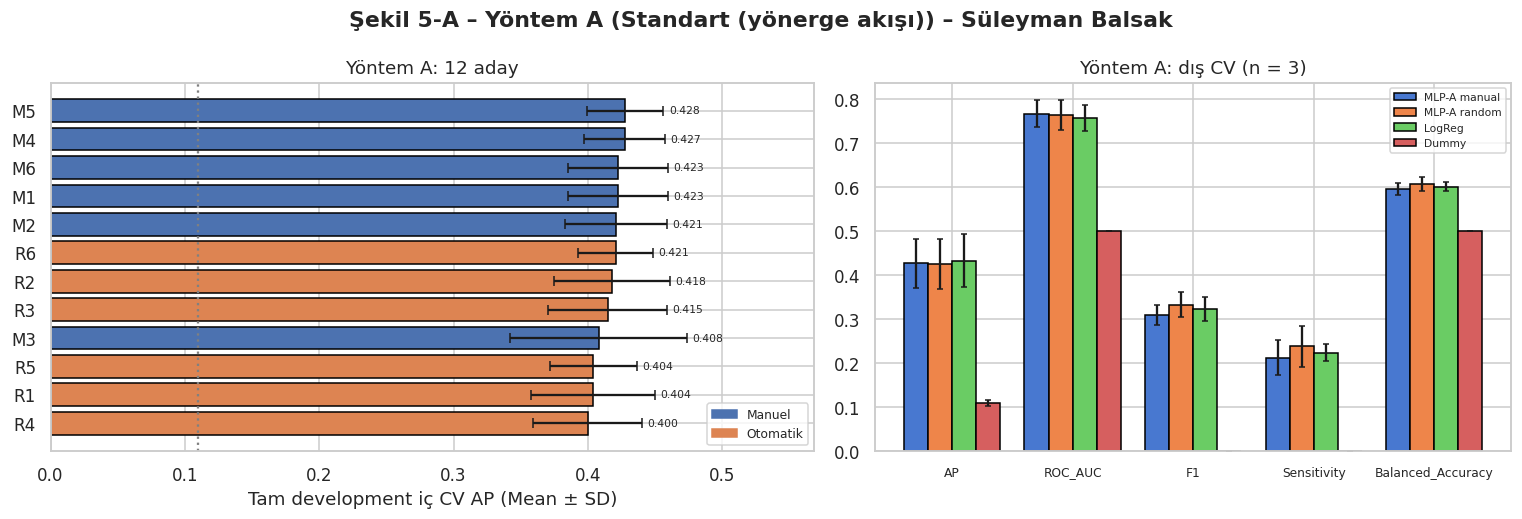

In [8]:
run_and_show("A")

In [9]:
# Yöntem A'ya özgü: optimizer davranışı (iç CV eğitimleri)
inner = RES["A"]["nested"]["inner"]
display(inner.groupby("optimizer").agg(n=("inner_AP", "size"), ort_AP=("inner_AP", "mean"),
        medyan_en_iyi_epoch=("best_epoch", "median"), ort_LR_dusus=("n_lr_drops", "mean"),
        ort_sure_sn=("elapsed_sec", "mean")).round(4))
m16 = inner[inner.config_id.isin(["M1", "M6"])].pivot_table(index=["outer_fold", "inner_fold"], columns="config_id",
                                                             values="inner_AP")
print(f"M1 (scheduler açık) − M6 (kapalı) iç AP farkı: ortalama {(m16['M1'] - m16['M6']).mean():+.5f} | "
      f"birebir aynı kat: {int(((m16['M1'] - m16['M6']).abs() < 1e-9).sum())}/{len(m16)}")

,n,ort_AP,medyan_en_iyi_epoch,ort_LR_dusus,ort_sure_sn
optimizer,,,,,
Adam,27,0.4190,25.0,2.2222,1.9280
AdamW,54,0.4151,16.0,1.7778,1.2317
SGD,27,0.4091,10.0,1.6296,1.6657


M1 (scheduler açık) − M6 (kapalı) iç AP farkı: ortalama +0.00010 | birebir aynı kat: 8/9


### Yorum – Süleyman Balsak
*Yukarıdaki tablolara ve Şekil 5-A'ye dayanarak kendi cümlelerinizle yanıtlayın; bu metin raporda Yöntem A alt bölümü olur.*

1. Nihai seçilen aday hangisi ve neden (iç CV AP, SD)? Manuel ve otomatik aramanın en iyileri arasındaki fark SD'den büyük mü?
2. SGD (M3) aynı LR'de Adam/AdamW'ye göre nasıl davrandı (en iyi epoch, süre)? M1 ile M6 neden aynı/farklı çıktı?
3. Dış CV'de MLP, Logistic Regression'ı geçti mi? Fark kat-arası SD ile karşılaştırıldığında anlamlı mı?

*Yanıt:* …

---
## 3. Yöntem B — Seda Erten

In [10]:
display(Markdown(f"**Yöntem:** {METHODS['B']['name']}  \n**Sorumlu üye:** {OWNER['B']}  \n"
                 f"**Nasıl yapıldı:** {METHODS['B']['how']}  \n**Hipotez:** {METHODS['B']['hypothesis']}  \n"
                 f"**Çıktılar:** `results/method_B/`, Tablo 2-B…5-B, Şekil 5-B"))

**Yöntem:** Sınıf ağırlıklı kayıp  
**Sorumlu üye:** Seda Erten  
**Nasıl yapıldı:** Her eğitimde eğitim kaybı `BCEWithLogitsLoss(pos_weight = neg/pos)` olur. Oran, o eğitimin fit alt kümesinden hesaplanır (kat-içi, sızıntısız). Early stopping ve scheduler ağırlıksız BCE'yi izler. Eşik 0.50.  
**Hipotez:** Azınlık sınıfa daha fazla ağırlık vermek 0.50 eşiğinde Sensitivity'yi belirgin artırır, sıralama metriği AP'yi az değiştirir, olasılık kalibrasyonunu (Brier) bozar.  
**Çıktılar:** `results/method_B/`, Tablo 2-B…5-B, Şekil 5-B

[B] dış kat 1 tamam (65 sn) | seçim: manual→M4, random→R4
[B] dış kat 2 tamam (131 sn) | seçim: manual→M3, random→R4
[B] dış kat 3 tamam (181 sn) | seçim: manual→M3, random→R2
Yöntem B: 243 sn | önbellekten gelen iç eğitim: 0/108


**Tablo 2-B – Manuel arama (M1–M6), tam development iç CV**

,config_id,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,use_scheduler,clip_outliers,unknown_strategy,n_params,mean_AP,sd_AP,mean_best_epoch,total_time_sec
3,M4,AdamW,[32],ReLU,0.001,0.0001,64,MinMaxScaler,0.0,True,False,keep_category,2049.0,0.4249,0.0367,10.0000,2.4553
2,M3,SGD,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,2049.0,0.4096,0.0544,57.6667,6.8310
0,M1,AdamW,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,2049.0,0.4093,0.0299,35.0000,4.7961
1,M2,Adam,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,2049.0,0.4062,0.0309,24.3333,3.8228
4,M5,AdamW,"[64, 32]",ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,6145.0,0.3923,0.0041,19.6667,4.2777
5,M6,AdamW,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,False,False,keep_category,2049.0,0.3921,0.0115,51.6667,7.8009


**Tablo 3-B – Otomatik arama (R1–R6), tam development iç CV**

,config_id,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,use_scheduler,clip_outliers,unknown_strategy,n_params,mean_AP,sd_AP,mean_best_epoch,total_time_sec
11,R6,AdamW,[64],tanh,0.0006,0.0001,32,MinMaxScaler,0.0,True,True,keep_category,4097.0,0.4167,0.0358,5.3333,5.0679
8,R3,Adam,[32],tanh,0.0008,0.0000,64,RobustScaler,0.0,True,False,keep_category,2049.0,0.4148,0.0452,16.6667,3.3698
9,R4,Adam,"[128, 64]",tanh,0.0001,0.0000,32,StandardScaler,0.2,True,True,most_frequent,15617.0,0.4123,0.0407,19.6667,11.0957
6,R1,SGD,"[128, 64]",ReLU,0.0530,0.0001,32,MinMaxScaler,0.0,True,False,most_frequent,15617.0,0.3994,0.0203,5.6667,3.8735
7,R2,SGD,[32],ReLU,0.0226,0.0001,32,StandardScaler,0.2,True,True,most_frequent,1857.0,0.3933,0.0332,5.3333,3.2678
10,R5,AdamW,"[128, 64]",ReLU,0.0010,0.0001,128,RobustScaler,0.0,True,True,most_frequent,15617.0,0.3808,0.0342,24.3333,3.3147


**Tablo 4-B – Dış kat bazlı sonuçlar** (eşik: 0.50)

,search,outer_fold,selected_config,inner_mean_AP,threshold,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy,TP,FP,TN,FN
0,manual,1,M4,0.4209,0.5,0.3707,0.7421,0.4084,0.6000,0.8217,0.7109,78,174,802,52
1,random,1,R4,0.4246,0.5,0.3717,0.7491,0.4086,0.5846,0.8299,0.7073,76,166,810,54
2,manual,2,M3,0.4170,0.5,0.4027,0.7691,0.4140,0.6017,0.8427,0.7222,71,154,825,47
3,random,2,R4,0.4431,0.5,0.4092,0.7603,0.4094,0.5932,0.8427,0.7180,70,154,825,48
4,manual,3,M3,0.3909,0.5,0.4932,0.8090,0.4484,0.6667,0.8489,0.7578,76,149,837,38
5,random,3,R2,0.3859,0.5,0.4758,0.8055,0.5000,0.5614,0.9209,0.7411,64,78,908,50


**Tablo 5-B – Dış CV Mean ± SD (n = 3)**

,grp,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy
0,MLP-B manual,0.4222 ± 0.0636,0.7734 ± 0.0337,0.4236 ± 0.0217,0.6228 ± 0.0380,0.8378 ± 0.0142,0.7303 ± 0.0245
1,MLP-B random,0.4189 ± 0.0527,0.7716 ± 0.0299,0.4393 ± 0.0526,0.5797 ± 0.0165,0.8645 ± 0.0493,0.7221 ± 0.0173
2,Dummy,0.1096 ± 0.0072,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5000 ± 0.0000
3,LogReg,0.4332 ± 0.0603,0.7579 ± 0.0305,0.3239 ± 0.0269,0.2243 ± 0.0195,0.9796 ± 0.0124,0.6019 ± 0.0104


**Yöntem B nihai seçimi:** M4 (manual_search) – iç CV AP = 0.4249 ± 0.0367 · eşik = 0.500  
En iyi manuel: M4 (0.4249) · En iyi otomatik: R6 (0.4167)

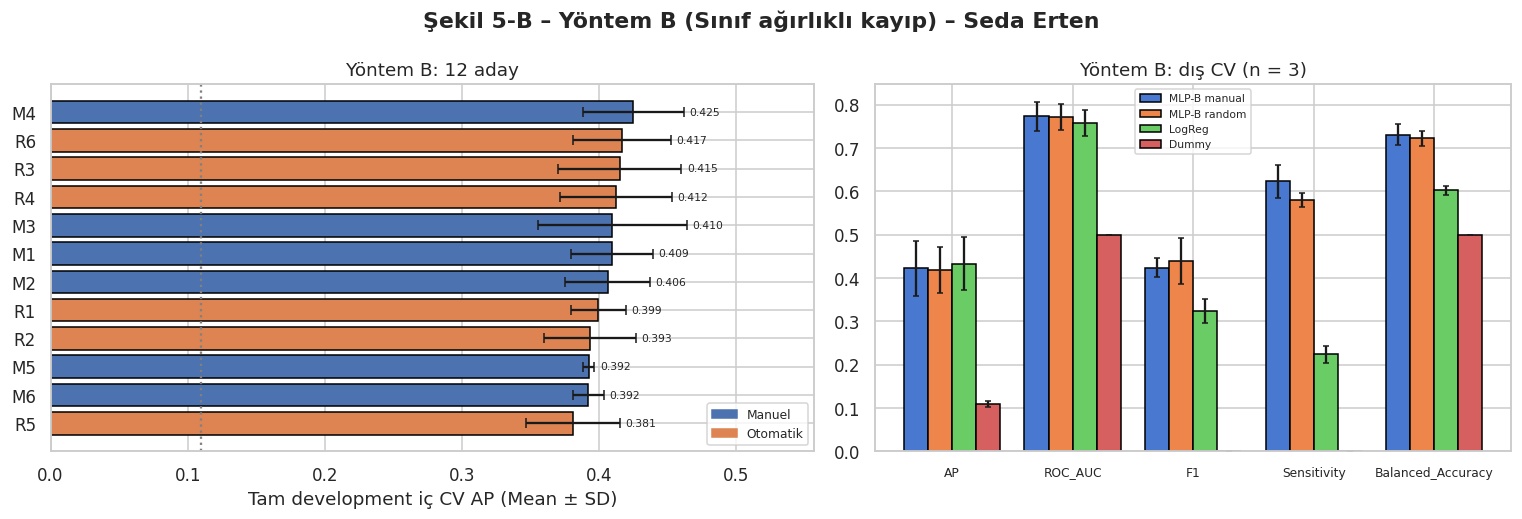

In [11]:
run_and_show("B")

In [12]:
# Yöntem B'ye özgü: kullanılan pos_weight değerleri ve A ile kat-eşleştirmeli karşılaştırma
print("Kullanılan pos_weight (fit alt kümesinde neg/pos):",
      RES["B"]["nested"]["inner"]["pos_weight_used"].describe()[["min", "mean", "max"]].round(3).to_dict())
if "A" in RES:
    a = RES["A"]["nested"]["outer"].set_index(["search", "outer_fold"])
    b = RES["B"]["nested"]["outer"].set_index(["search", "outer_fold"])
    cmp_ = pd.DataFrame({m: b[m] - a[m] for m in ["AP", "ROC_AUC", "Sensitivity", "Specificity", "F1", "Brier"]})
    display(Markdown("**B − A farkı (aynı dış kat, aynı arama)**")); display(cmp_.round(4))

Kullanılan pos_weight (fit alt kümesinde neg/pos): {'min': 7.503, 'mean': 8.148, 'max': 8.913}


**B − A farkı (aynı dış kat, aynı arama)**

,,AP,ROC_AUC,Sensitivity,Specificity,F1,Brier
search,outer_fold,,,,,,
manual,1,-0.0187,-0.0059,0.3923,-0.1578,0.1033,0.0840
random,1,-0.0095,0.0066,0.3154,-0.1352,0.0568,0.0837
manual,2,0.0003,0.0156,0.3475,-0.1256,0.0788,0.0819
random,2,0.0039,0.0116,0.3305,-0.1277,0.0610,0.0823
manual,3,0.0014,0.0066,0.4912,-0.1471,0.1585,0.0791
random,3,-0.0148,0.0021,0.3772,-0.0740,0.2000,0.0436


### Yorum – Seda Erten
*Yukarıdaki tablolara ve Şekil 5-B'ye dayanarak kendi cümlelerinizle yanıtlayın; bu metin raporda Yöntem B alt bölümü olur.*

1. pos_weight 0.50 eşiğindeki Sensitivity ve Specificity'yi nasıl değiştirdi? Hipotez doğrulandı mı?
2. AP ve ROC-AUC'deki değişim neden küçük/büyük? Sınıf ağırlığı sıralamayı mı, yoksa olasılık ölçeğini mi değiştiriyor?
3. Brier skorundaki değişim kalibrasyon hakkında ne söylüyor? Bu yöntem hangi kullanım senaryosunda tercih edilir?

*Yanıt:* …

---
## 4. Yöntem C — İlkin Urcan

In [13]:
display(Markdown(f"**Yöntem:** {METHODS['C']['name']}  \n**Sorumlu üye:** {OWNER['C']}  \n"
                 f"**Nasıl yapıldı:** {METHODS['C']['how']}  \n**Hipotez:** {METHODS['C']['hypothesis']}  \n"
                 f"**Çıktılar:** `results/method_C/`, Tablo 2-C…5-C, Şekil 5-C"))

**Yöntem:** İç CV'de seçilen karar eşiği  
**Sorumlu üye:** İlkin Urcan  
**Nasıl yapıldı:** Model eğitimi ve aday seçimi Yöntem A ile aynıdır (aynı ağırlıklar). Fark karar kuralındadır: seçilen adayın iç CV out-of-fold tahminlerinde F1'i en yüksek yapan eşik seçilir ve dış değerlendirme ile testte bu eşik kullanılır. Eşik hiçbir zaman değerlendirme/test verisiyle seçilmez.  
**Hipotez:** Dengesiz veride 0.50 eşiği gereğinden yüksektir. İç CV ile seçilen eşik AP'yi değiştirmeden F1, Sensitivity ve Balanced Accuracy'yi artırır.  
**Çıktılar:** `results/method_C/`, Tablo 2-C…5-C, Şekil 5-C

[C] dış kat 1 tamam (1 sn) | seçim: manual→M1, random→R1
[C] dış kat 2 tamam (2 sn) | seçim: manual→M1, random→R3
[C] dış kat 3 tamam (2 sn) | seçim: manual→M2, random→R2
Yöntem C: 4 sn | önbellekten gelen iç eğitim: 108/108


**Tablo 2-C – Manuel arama (M1–M6), tam development iç CV**

,config_id,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,use_scheduler,clip_outliers,unknown_strategy,n_params,mean_AP,sd_AP,mean_best_epoch,total_time_sec
4,M5,AdamW,"[64, 32]",ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,6145.0,0.4279,0.0283,8.0000,3.2243
3,M4,AdamW,[32],ReLU,0.001,0.0001,64,MinMaxScaler,0.0,True,False,keep_category,2049.0,0.4273,0.0303,11.0000,2.5352
5,M6,AdamW,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,False,False,keep_category,2049.0,0.4226,0.0372,13.6667,3.8476
0,M1,AdamW,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,2049.0,0.4226,0.0372,13.6667,2.7987
1,M2,Adam,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,2049.0,0.4209,0.0377,12.0000,2.9729
2,M3,SGD,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,False,keep_category,2049.0,0.4080,0.0657,106.6667,9.5550


**Tablo 3-C – Otomatik arama (R1–R6), tam development iç CV**

,config_id,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,use_scheduler,clip_outliers,unknown_strategy,n_params,mean_AP,sd_AP,mean_best_epoch,total_time_sec
11,R6,AdamW,[64],tanh,0.0006,0.0001,32,MinMaxScaler,0.0,True,True,keep_category,4097.0,0.4207,0.0279,7.3333,4.7325
7,R2,SGD,[32],ReLU,0.0226,0.0001,32,StandardScaler,0.2,True,True,most_frequent,1857.0,0.4179,0.0430,4.3333,3.1008
8,R3,Adam,[32],tanh,0.0008,0.0000,64,RobustScaler,0.0,True,False,keep_category,2049.0,0.4147,0.0442,11.6667,2.6173
10,R5,AdamW,"[128, 64]",ReLU,0.0010,0.0001,128,RobustScaler,0.0,True,True,most_frequent,15617.0,0.4040,0.0326,11.0000,2.0596
6,R1,SGD,"[128, 64]",ReLU,0.0530,0.0001,32,MinMaxScaler,0.0,True,False,most_frequent,15617.0,0.4037,0.0461,5.3333,3.6838
9,R4,Adam,"[128, 64]",tanh,0.0001,0.0000,32,StandardScaler,0.2,True,True,most_frequent,15617.0,0.3998,0.0405,18.3333,10.9196


**Tablo 4-C – Dış kat bazlı sonuçlar** (eşik: iç CV OOF F1-optimal)

,search,outer_fold,selected_config,inner_mean_AP,threshold,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy,TP,FP,TN,FN
0,manual,1,M1,0.4405,0.2113,0.3894,0.7480,0.4397,0.4769,0.9078,0.6924,62,90,886,68
1,random,1,R1,0.4304,0.1822,0.3812,0.7424,0.4286,0.4615,0.9078,0.6847,60,90,886,70
2,manual,2,M1,0.4307,0.2153,0.4024,0.7535,0.4556,0.5000,0.9162,0.7081,59,82,897,59
3,random,2,R3,0.4386,0.2159,0.4053,0.7487,0.4531,0.4915,0.9183,0.7049,58,80,899,60
4,manual,3,M2,0.4089,0.1939,0.4919,0.8024,0.5020,0.5439,0.9280,0.7359,62,71,915,52
5,random,3,R2,0.3952,0.1484,0.4907,0.8034,0.4945,0.5965,0.9057,0.7511,68,93,893,46


**Tablo 5-C – Dış CV Mean ± SD (n = 3)**

,grp,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy
0,MLP-C manual,0.4279 ± 0.0558,0.7679 ± 0.0299,0.4658 ± 0.0324,0.5069 ± 0.0340,0.9173 ± 0.0101,0.7121 ± 0.0221
1,MLP-C random,0.4257 ± 0.0575,0.7648 ± 0.0335,0.4587 ± 0.0333,0.5165 ± 0.0709,0.9106 ± 0.0068,0.7136 ± 0.0340
2,Dummy,0.1096 ± 0.0072,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5000 ± 0.0000
3,LogReg,0.4332 ± 0.0603,0.7579 ± 0.0305,0.3239 ± 0.0269,0.2243 ± 0.0195,0.9796 ± 0.0124,0.6019 ± 0.0104


**Yöntem C nihai seçimi:** M5 (manual_search) – iç CV AP = 0.4279 ± 0.0283 · eşik = 0.154  
En iyi manuel: M5 (0.4279) · En iyi otomatik: R6 (0.4207)

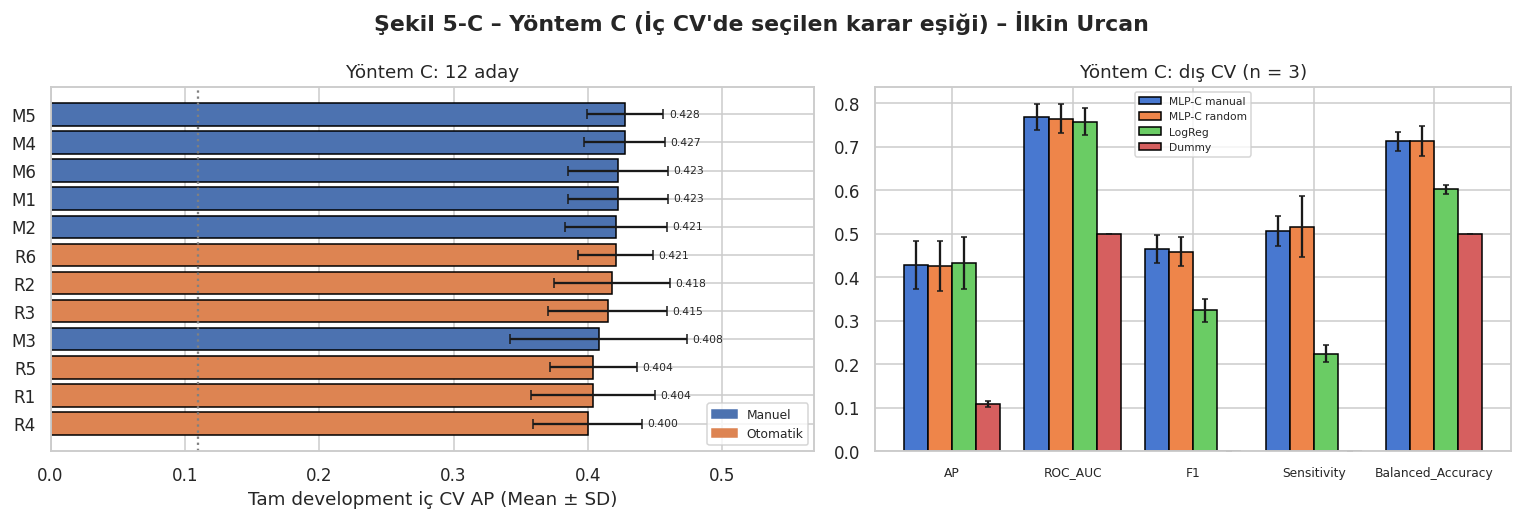

In [14]:
run_and_show("C")

In [15]:
# Yöntem C'ye özgü: dış katlarda iç CV ile seçilen eşikler ve A (0.50) ile karşılaştırma
sel = RES["C"]["nested"]["selection"]
display(sel)
if "A" in RES:
    a = RES["A"]["nested"]["outer"].set_index(["search", "outer_fold"])
    c_ = RES["C"]["nested"]["outer"].set_index(["search", "outer_fold"])
    cmp_ = pd.concat({"A (0.50)": a[["threshold", "AP", "F1", "Sensitivity", "Specificity", "Balanced_Accuracy"]],
                      "C (iç CV eşiği)": c_[["threshold", "AP", "F1", "Sensitivity", "Specificity", "Balanced_Accuracy"]]},
                     axis=1)
    display(cmp_.round(4))
    print("Not: AP ve ROC-AUC eşikten bağımsızdır; A ve C'de aynıdır. Fark yalnızca eşiğe bağlı metriklerdedir.")

,method,outer_fold,search,selected_config,inner_mean_AP,threshold
0,C,1,manual,M1,0.440498,0.211265
1,C,1,random,R1,0.430398,0.182227
2,C,2,manual,M1,0.430689,0.215340
3,C,2,random,R3,0.438617,0.215897
4,C,3,manual,M2,0.408935,0.193900
5,C,3,random,R2,0.395216,0.148414


A (0.50)                                                           C (iç CV eşiği)                                                          
                  threshold      AP      F1 Sensitivity Specificity Balanced_Accuracy       threshold      AP      F1 Sensitivity Specificity Balanced_Accuracy
search outer_fold                                                                                                                                              
manual 1                0.5  0.3894  0.3051      0.2077      0.9795            0.5936          0.2113  0.3894  0.4397      0.4769      0.9078            0.6924
random 1                0.5  0.3812  0.3518      0.2692      0.9652            0.6172          0.1822  0.3812  0.4286      0.4615      0.9078            0.6847
manual 2                0.5  0.4024  0.3352      0.2542      0.9683            0.6113          0.2153  0.4024  0.4556      0.5000      0.9162            0.7081
random 2                0.5  0.4053  0.3483      0.2627      0.9704            0.6165          0.2159  0.4053  0.4531      0.4915      0.9183            0.7049
manual 3                0.5  0.4919  0.2899      0.1754      0.9959            0.5857          0.1939  0.4919  0.5020      0.5439      0.9280            0.7359
random 3                0.5  0.4907  0.3000      0.1842      0.9949            0.5896          0.1484  0.4907  0.4945      0.5965      0.9057            0.7511

Not: AP ve ROC-AUC eşikten bağımsızdır; A ve C'de aynıdır. Fark yalnızca eşiğe bağlı metriklerdedir.


### Yorum – İlkin Urcan
*Yukarıdaki tablolara ve Şekil 5-C'ye dayanarak kendi cümlelerinizle yanıtlayın; bu metin raporda Yöntem C alt bölümü olur.*

1. Dış katlarda seçilen eşikler ne kadar tutarlı? 0.50'ye göre ne kadar düşük?
2. Eşik değişince F1, Sensitivity ve Balanced Accuracy nasıl değişti? AP neden değişmedi?
3. Eşiği test yerine iç CV ile seçmek neden zorunlu? Banka kampanyası bağlamında FN ve FP'nin maliyetini tartışın.

*Yanıt:* …

---
## 5. Yöntem D — Aslıhan Semiz Varlı

In [16]:
display(Markdown(f"**Yöntem:** {METHODS['D']['name']}  \n**Sorumlu üye:** {OWNER['D']}  \n"
                 f"**Nasıl yapıldı:** {METHODS['D']['how']}  \n**Hipotez:** {METHODS['D']['hypothesis']}  \n"
                 f"**Çıktılar:** `results/method_D/`, Tablo 2-D…5-D, Şekil 5-D"))

**Yöntem:** Alternatif ön işleme  
**Sorumlu üye:** Aslıhan Semiz Varlı  
**Nasıl yapıldı:** Tüm adaylarda `unknown` kategorileri kat-içi en sık sınıfla doldurulur, sayısal değişkenler eğitim katında öğrenilen P1–P99 sınırlarıyla kırpılır, `pdays` ham kodlamasıyla (999 dahil) kullanılır ve `prev_contacted` göstergesi eklenmez. Diğer her şey A ile aynıdır. Eşik 0.50.  
**Hipotez:** `unknown`'ı bilgi taşıyan ayrı bir kategori olarak tutmak ve `pdays` özel kodunu ayrı göstermek bilgi kaybını önler. Bu yüzden D'nin AP'si A'dan eşit veya düşük olur.  
**Çıktılar:** `results/method_D/`, Tablo 2-D…5-D, Şekil 5-D

[D] dış kat 1 tamam (64 sn) | seçim: manual→M3, random→R5
[D] dış kat 2 tamam (127 sn) | seçim: manual→M4, random→R6
[D] dış kat 3 tamam (170 sn) | seçim: manual→M3, random→R2
Yöntem D: 227 sn | önbellekten gelen iç eğitim: 0/108


**Tablo 2-D – Manuel arama (M1–M6), tam development iç CV**

,config_id,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,use_scheduler,clip_outliers,unknown_strategy,n_params,mean_AP,sd_AP,mean_best_epoch,total_time_sec
3,M4,AdamW,[32],ReLU,0.001,0.0001,64,MinMaxScaler,0.0,True,True,most_frequent,1825.0,0.4244,0.0225,14.3333,3.0565
2,M3,SGD,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,True,most_frequent,1825.0,0.4233,0.0413,123.6667,10.4561
4,M5,AdamW,"[64, 32]",ReLU,0.001,0.0001,64,StandardScaler,0.0,True,True,most_frequent,5697.0,0.4219,0.0335,8.0000,2.8632
5,M6,AdamW,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,False,True,most_frequent,1825.0,0.4215,0.0207,12.3333,2.6701
0,M1,AdamW,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,True,most_frequent,1825.0,0.4215,0.0207,12.3333,3.3333
1,M2,Adam,[32],ReLU,0.001,0.0001,64,StandardScaler,0.0,True,True,most_frequent,1825.0,0.4209,0.0231,12.3333,2.6869


**Tablo 3-D – Otomatik arama (R1–R6), tam development iç CV**

,config_id,optimizer,hidden_layers,activation,lr,weight_decay,batch_size,scaler,dropout,use_scheduler,clip_outliers,unknown_strategy,n_params,mean_AP,sd_AP,mean_best_epoch,total_time_sec
11,R6,AdamW,[64],tanh,0.0006,0.0001,32,MinMaxScaler,0.0,True,True,most_frequent,3649.0,0.4263,0.0273,8.6667,4.5263
7,R2,SGD,[32],ReLU,0.0226,0.0001,32,StandardScaler,0.2,True,True,most_frequent,1825.0,0.4246,0.0330,6.6667,3.9373
10,R5,AdamW,"[128, 64]",ReLU,0.0010,0.0001,128,RobustScaler,0.0,True,True,most_frequent,15489.0,0.4226,0.0545,12.6667,2.4514
9,R4,Adam,"[128, 64]",tanh,0.0001,0.0000,32,StandardScaler,0.2,True,True,most_frequent,15489.0,0.4210,0.0442,15.0000,10.2804
6,R1,SGD,"[128, 64]",ReLU,0.0530,0.0001,32,MinMaxScaler,0.0,True,True,most_frequent,15489.0,0.4099,0.0042,8.3333,5.2662
8,R3,Adam,[32],tanh,0.0008,0.0000,64,RobustScaler,0.0,True,True,most_frequent,1825.0,0.3714,0.0180,14.6667,2.9026


**Tablo 4-D – Dış kat bazlı sonuçlar** (eşik: 0.50)

,search,outer_fold,selected_config,inner_mean_AP,threshold,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy,TP,FP,TN,FN
0,manual,1,M3,0.4379,0.5,0.3883,0.7511,0.2722,0.1769,0.9836,0.5803,23,16,960,107
1,random,1,R5,0.4435,0.5,0.3531,0.7474,0.2824,0.1846,0.9836,0.5841,24,16,960,106
2,manual,2,M4,0.4307,0.5,0.3995,0.7570,0.3333,0.2458,0.9724,0.6091,29,27,952,89
3,random,2,R6,0.4352,0.5,0.4022,0.7516,0.3295,0.2458,0.9704,0.6081,29,29,950,89
4,manual,3,M3,0.4038,0.5,0.4640,0.7941,0.3000,0.1842,0.9949,0.5896,21,5,981,93
5,random,3,R2,0.4040,0.5,0.4949,0.8061,0.2899,0.1754,0.9959,0.5857,20,4,982,94


**Tablo 5-D – Dış CV Mean ± SD (n = 3)**

,grp,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy
0,MLP-D manual,0.4173 ± 0.0409,0.7674 ± 0.0233,0.3018 ± 0.0306,0.2023 ± 0.0378,0.9837 ± 0.0113,0.5930 ± 0.0147
1,MLP-D random,0.4167 ± 0.0720,0.7683 ± 0.0328,0.3006 ± 0.0254,0.2019 ± 0.0382,0.9833 ± 0.0128,0.5926 ± 0.0134
2,Dummy,0.1096 ± 0.0072,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5000 ± 0.0000
3,LogReg,0.4332 ± 0.0603,0.7579 ± 0.0305,0.3239 ± 0.0269,0.2243 ± 0.0195,0.9796 ± 0.0124,0.6019 ± 0.0104


**Yöntem D nihai seçimi:** R6 (random_search) – iç CV AP = 0.4263 ± 0.0273 · eşik = 0.500  
En iyi manuel: M4 (0.4244) · En iyi otomatik: R6 (0.4263)

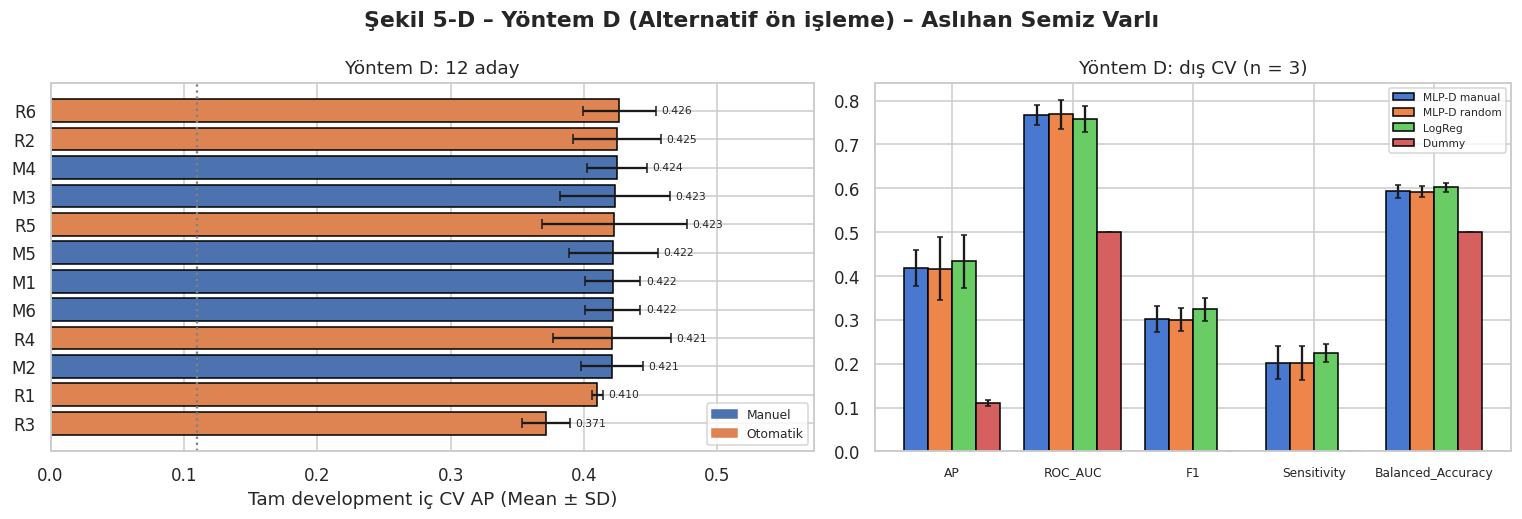

In [17]:
run_and_show("D")

In [18]:
# Yöntem D'ye özgü: ön işleme farkı ve aday bazında A ile iç CV AP karşılaştırması
display(pd.DataFrame([{"Ayar": "unknown", "A": "ayrı kategori (M1–M6)", "D": "kat-içi en sık sınıf"},
                      {"Ayar": "clipping", "A": "yok (M1–M6)", "D": "eğitim katında P1–P99"},
                      {"Ayar": "pdays", "A": "999 → prev_contacted + 0", "D": "ham (999 dahil), gösterge yok"}]))
if "A" in RES:
    sa = RES["A"]["full"]["summary"].set_index("config_id")["mean_AP"]
    sd_ = RES["D"]["full"]["summary"].set_index("config_id")["mean_AP"]
    t = pd.DataFrame({"A_AP": sa, "D_AP": sd_}).assign(fark_D_eksi_A=lambda x: x.D_AP - x.A_AP)
    display(t.round(4))
    print(f"D, 12 adayın {int((t.fark_D_eksi_A > 0).sum())} tanesinde A'dan yüksek iç CV AP verdi.")

,Ayar,A,D
0,unknown,ayrı kategori (M1–M6),kat-içi en sık sınıf
1,clipping,yok (M1–M6),eğitim katında P1–P99
2,pdays,999 → prev_contacted + 0,"ham (999 dahil), gösterge yok"


,A_AP,D_AP,fark_D_eksi_A
config_id,,,
M1,0.4226,0.4215,-0.0011
M2,0.4209,0.4209,-0.0000
M3,0.4080,0.4233,0.0154
M4,0.4273,0.4244,-0.0029
M5,0.4279,0.4219,-0.0060
M6,0.4226,0.4215,-0.0011
R1,0.4037,0.4099,0.0062
R2,0.4179,0.4246,0.0068
R3,0.4147,0.3714,-0.0433


D, 12 adayın 6 tanesinde A'dan yüksek iç CV AP verdi.


### Yorum – Aslıhan Semiz Varlı
*Yukarıdaki tablolara ve Şekil 5-D'ye dayanarak kendi cümlelerinizle yanıtlayın; bu metin raporda Yöntem D alt bölümü olur.*

1. Alternatif ön işleme iç CV ve dış CV AP'sini A'ya göre nasıl etkiledi? Hipotez doğrulandı mı?
2. Hangi adaylar D'den en çok etkilendi (ör. RobustScaler kullananlar)? `pdays` ham kodlamasının etkisini tartışın.
3. `unknown`'ı en sık sınıfla doldurmak hangi bilgiyi kaybettiriyor olabilir (`default` sütunu)?

*Yanıt:* …

---
## 6. Dört yöntemin development karşılaştırması ve birincil yöntem
**Önceden tanımlı kural:** Birincil yöntem, nihai konfigürasyonunun **tam development iç CV mean AP**'si en yüksek olan yöntemdir. Eşitlikte düşük SD, o da eşitse sıra A → B → C → D. C, A ile aynı modeli kullandığı için AP'si A'ya eşittir ve eşitlikte A seçilir. Dış CV ve test sonuçları bu seçimde **kullanılmaz**. Dört yöntemin hepsi 03'te kilitlenir ve raporlanır.

In [19]:
assert set(RES) == set(METHOD_ORDER), "Önce dört yöntem bölümünün hepsini çalıştırın."
finals = {m: RES[m]["full"]["final"] for m in METHOD_ORDER}
rank = sorted(METHOD_ORDER, key=lambda m: (-finals[m]["full_dev_mean_AP"], finals[m]["full_dev_sd_AP"], METHOD_ORDER.index(m)))
PRIMARY = rank[0]

final_doc = {
    "primary_method": PRIMARY,
    "primary_rule": "tam development iç CV mean AP en yüksek (eşitlikte düşük SD, sonra A→B→C→D); dış CV/test kullanılmadı",
    "threshold_default": TRAINING_SETTINGS["threshold"],
    "methods": {m: dict(finals[m], owner=OWNER[m]) for m in METHOD_ORDER},
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
}
save_json(final_doc, "results/final_hyperparameters.json")

dev_tbl = pd.DataFrame([{"Yöntem": m, "Üye": OWNER[m], "Ad": METHODS[m]["name"], "Nihai aday": finals[m]["config_id"],
                         "Arama": finals[m]["selected_search"], "İç CV AP": finals[m]["full_dev_mean_AP"],
                         "SD": finals[m]["full_dev_sd_AP"], "Eşik": finals[m]["threshold"],
                         "Birincil": "✓" if m == PRIMARY else ""} for m in METHOD_ORDER])
dev_tbl.to_csv("results/methods_dev_comparison.csv", index=False)
display(dev_tbl.round(4))
print(f">>> Birincil yöntem: {PRIMARY} ({METHODS[PRIMARY]['name']}) – {OWNER[PRIMARY]}")

# Yönergenin istediği birleşik dosyalar
all_summ = pd.concat([RES[m]["full"]["summary"] for m in METHOD_ORDER], ignore_index=True)
all_summ[all_summ.search_type == "manual"].to_csv("results/manual_search_results.csv", index=False)
all_summ[all_summ.search_type == "random"].to_csv("results/random_search_results.csv", index=False)
outer_all = pd.concat([RES[m]["nested"]["outer"] for m in METHOD_ORDER] + [refs], ignore_index=True)
outer_all.to_csv("results/outer_cv_results.csv", index=False)
outer_all["grp"] = np.where(outer_all["method"].isin(["Dummy", "LogReg"]), outer_all["method"],
                            "MLP-" + outer_all["method"] + " " + outer_all["search"])
outer_summary = mean_sd_table(outer_all, "grp")
outer_summary.to_csv("results/outer_cv_summary_mean_sd.csv", index=False)
display(outer_summary[["grp", "AP", "ROC_AUC", "F1", "Sensitivity", "Specificity", "Balanced_Accuracy", "Brier"]])

,Yöntem,Üye,Ad,Nihai aday,Arama,İç CV AP,SD,Eşik,Birincil
0,A,Süleyman Balsak,Standart (yönerge akışı),M5,manual_search,0.4279,0.0283,0.5000,✓
1,B,Seda Erten,Sınıf ağırlıklı kayıp,M4,manual_search,0.4249,0.0367,0.5000,
2,C,İlkin Urcan,İç CV'de seçilen karar eşiği,M5,manual_search,0.4279,0.0283,0.1538,
3,D,Aslıhan Semiz Varlı,Alternatif ön işleme,R6,random_search,0.4263,0.0273,0.5000,


>>> Birincil yöntem: A (Standart (yönerge akışı)) – Süleyman Balsak


,grp,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy,Brier
0,MLP-A manual,0.4279 ± 0.0558,0.7679 ± 0.0299,0.3100 ± 0.0231,0.2125 ± 0.0396,0.9813 ± 0.0139,0.5969 ± 0.0131,0.0809 ± 0.0090
1,MLP-A random,0.4257 ± 0.0575,0.7648 ± 0.0335,0.3334 ± 0.0289,0.2387 ± 0.0473,0.9768 ± 0.0159,0.6078 ± 0.0158,0.0816 ± 0.0098
2,MLP-B manual,0.4222 ± 0.0636,0.7734 ± 0.0337,0.4236 ± 0.0217,0.6228 ± 0.0380,0.8378 ± 0.0142,0.7303 ± 0.0245,0.1625 ± 0.0115
3,MLP-B random,0.4189 ± 0.0527,0.7716 ± 0.0299,0.4393 ± 0.0526,0.5797 ± 0.0165,0.8645 ± 0.0493,0.7221 ± 0.0173,0.1515 ± 0.0318
4,MLP-C manual,0.4279 ± 0.0558,0.7679 ± 0.0299,0.4658 ± 0.0324,0.5069 ± 0.0340,0.9173 ± 0.0101,0.7121 ± 0.0221,0.0809 ± 0.0090
5,MLP-C random,0.4257 ± 0.0575,0.7648 ± 0.0335,0.4587 ± 0.0333,0.5165 ± 0.0709,0.9106 ± 0.0068,0.7136 ± 0.0340,0.0816 ± 0.0098
6,MLP-D manual,0.4173 ± 0.0409,0.7674 ± 0.0233,0.3018 ± 0.0306,0.2023 ± 0.0378,0.9837 ± 0.0113,0.5930 ± 0.0147,0.0812 ± 0.0078
7,MLP-D random,0.4167 ± 0.0720,0.7683 ± 0.0328,0.3006 ± 0.0254,0.2019 ± 0.0382,0.9833 ± 0.0128,0.5926 ± 0.0134,0.0811 ± 0.0097
8,Dummy,0.1096 ± 0.0072,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5000 ± 0.0000,0.1096 ± 0.0072
9,LogReg,0.4332 ± 0.0603,0.7579 ± 0.0305,0.3239 ± 0.0269,0.2243 ± 0.0195,0.9796 ± 0.0124,0.6019 ± 0.0104,0.0807 ± 0.0100


### Şekil 5 – Dört yöntemin dış CV karşılaştırması

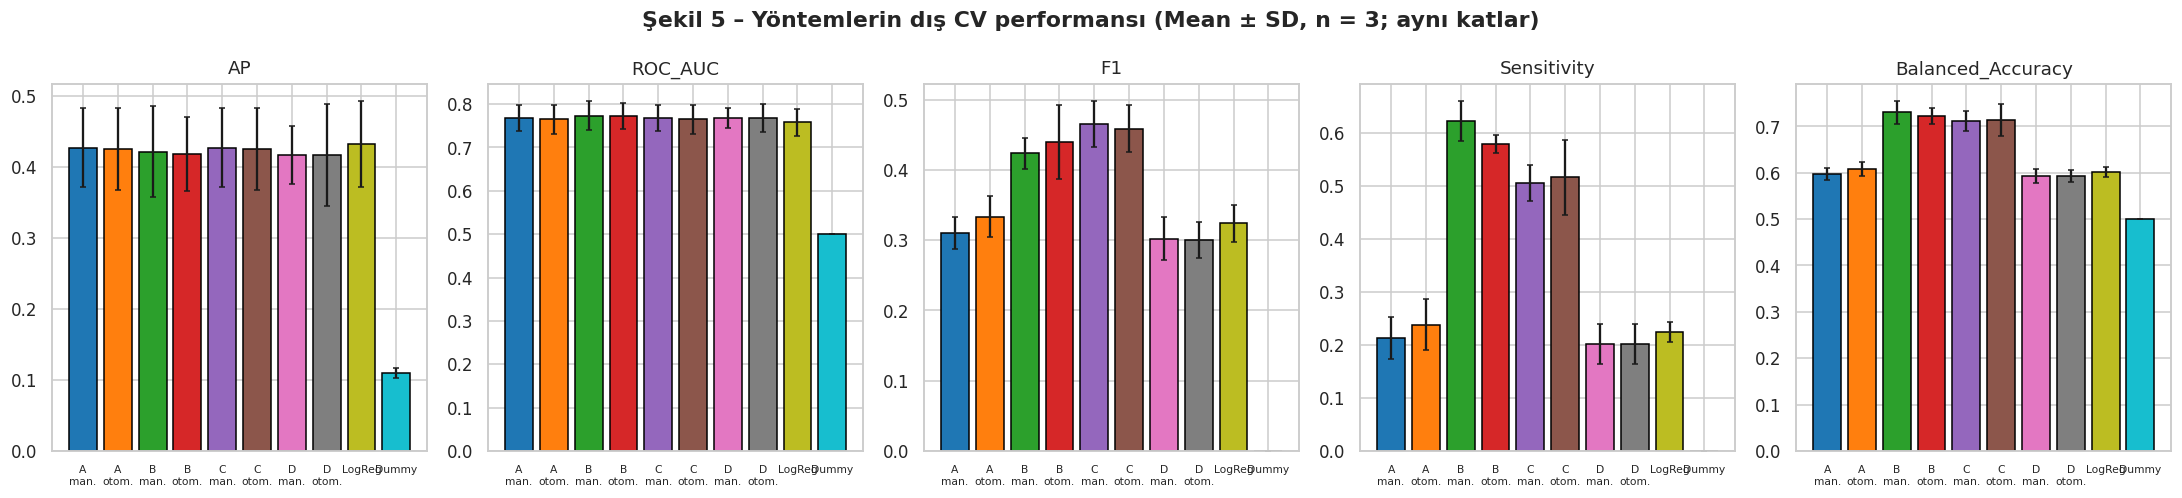

Uyarılı iç eğitim: 25 / 432


In [20]:
mets = ["AP", "ROC_AUC", "F1", "Sensitivity", "Balanced_Accuracy"]
groups = [g for m in METHOD_ORDER for g in (f"MLP-{m} manual", f"MLP-{m} random")] + ["LogReg", "Dummy"]
os_ = outer_summary.set_index("grp")
fig, axes = plt.subplots(1, len(mets), figsize=(20, 4.6), sharey=False)
pal = sns.color_palette("tab10", len(groups))
for ax, m in zip(axes, mets):
    ax.bar(range(len(groups)), [os_.loc[g, f"{m}_mean"] for g in groups],
           yerr=[os_.loc[g, f"{m}_sd"] for g in groups], color=pal, edgecolor="black", capsize=2)
    ax.set_title(m); ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([g.replace("MLP-", "").replace(" manual", "\nman.").replace(" random", "\notom.") for g in groups],
                       fontsize=7)
plt.suptitle("Şekil 5 – Yöntemlerin dış CV performansı (Mean ± SD, n = 3; aynı katlar)", fontweight="bold")
plt.tight_layout(); plt.savefig("figures/fig5_methods_outer_cv.png", dpi=300); plt.show()

all_runs = pd.concat([RES[m]["nested"]["inner"] for m in METHOD_ORDER], ignore_index=True)
warn = all_runs[all_runs["warnings"].fillna("") != ""][["method", "outer_fold", "inner_fold", "config_id", "status", "warnings"]]
warn.to_csv("results/training_warnings.csv", index=False)
print(f"Uyarılı iç eğitim: {len(warn)} / {len(all_runs)}")

### Ortak değerlendirme (grup birlikte yazar)
Dört yöntemin development sonuçlarını karşılaştırın: Hangi yöntem-düzeyi kural AP'yi (sıralamayı), hangisi eşiğe bağlı metrikleri (Sensitivity, F1) değiştirdi? Farklar kat-arası SD'den büyük mü? Birincil yöntem kuralının sonucu sizi şaşırttı mı?

*Yanıt:* …

> 03'e geçmeden önce `results/` ve `configs/` dosyalarını commit'leyin.